# GhostShield — Colab Pipeline

In Colab, run the setup cell below to mount Drive and verify packages. Prepare the data layout documented in README.md. The default
run performs raw EDA, preprocessing, saved-model diagnostics, tuned evaluation,
and a preprocessed-message inference example. Training and tuning are optional
because the final trained weights and measured results are included.


## View the saved results without running

EDA, preprocessing, saved-model diagnostics, tuned evaluation, and inference
show the outputs from the locally executed integrated notebook on the original
datasets. Two separately executed display cells show archived training and
tuning artifacts. Training and tuning branches were disabled in this run.
Setup-only cells and guarded training branches may have no visible output.
The output paths shown by the local run are historical. The hosted Colab
runtime was not used for this validation.

For a static copy, open the accompanying HTML file. Both files contain the
saved figures and tables.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import os
import subprocess
import sys

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    # Change this path if your submission folder is elsewhere in My Drive.
    project = Path('/content/drive/MyDrive/CarShield_AI_Final_Submission')
    if not (project / 'requirements-colab.txt').is_file():
        raise FileNotFoundError(f'Upload the complete submission folder to {project}')
    os.chdir(project)
    os.environ.setdefault('CARSHIELD_RUNS_DIR', '/content/carshield_runs')

    pins = (project / 'requirements-colab.txt').read_text().splitlines()
    missing = []
    for pin in pins:
        if not pin or pin.startswith('#'):
            continue
        package, expected = pin.split('==')
        try:
            installed = metadata.version(package)
        except metadata.PackageNotFoundError:
            installed = None
        if installed != expected:
            missing.append(pin)
    if missing:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r',
                               str(project / 'requirements-colab.txt')])
        print('Dependencies installed. Restart the session, then run all cells again.')
        raise RuntimeError('Restart the session before continuing.')
    print(f'Colab setup ready: Python {sys.version.split()[0]}')


In [2]:
from pathlib import Path
from tempfile import mkdtemp
from IPython.display import display
import os
import gc

RUN_RAW_EDA = True
TRAIN_BASELINES = False  # Enable only after approval.
RUN_TUNING = False       # Enable only after approval.

# Keep the project path stable when rerunning this cell in the same kernel.
PROJECT = globals().get('PROJECT', Path.cwd())
DATA_ROOT = Path(os.environ.get('CARSHIELD_DATA_ROOT', str(PROJECT))).resolve()
ARTIFACTS = DATA_ROOT / 'team_inputs'
RAW = ARTIFACTS / 'raw'
CLEAN_NAMES = ['normal', 'dos', 'fuzzy', 'gear', 'rpm']
RAW_NAMES = ['DoS_dataset.csv', 'Fuzzy_dataset.csv', 'gear_dataset.csv',
             'RPM_dataset.csv', 'normal_run_data.txt']
SAVED = PROJECT / 'models'
SCALED_TIME = DATA_ROOT / 'data'
TUNED_MODEL = SAVED / 'best_ae_time_12features.keras'
PLAIN_ZIP = ARTIFACTS / 'CAN_Bus_Preprocessed_Data.zip'
TIME_ZIP = ARTIFACTS / 'CAN_Bus_Preprocessed_Data_Time_Features.zip'

required = [PLAIN_ZIP, TIME_ZIP, SAVED / 'time_autoencoder.keras',
            SAVED / 'baseline_autoencoder.keras', TUNED_MODEL,
            SCALED_TIME / 'train_scaled_time.parquet', SCALED_TIME / 'validation_scaled_time.parquet']
required += [SCALED_TIME / f'{name}_test_scaled_time.parquet' for name in CLEAN_NAMES[1:]]
if RUN_RAW_EDA:
    required += [RAW / name for name in RAW_NAMES]
else:
    required += [ARTIFACTS / 'cleaned' / f'{name}.parquet' for name in CLEAN_NAMES]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError('Missing project inputs: ' + ', '.join(missing))

RUNS = Path(os.environ.get('CARSHIELD_RUNS_DIR', str(PROJECT / 'pipeline_runs'))).resolve()
RUNS.mkdir(parents=True, exist_ok=True)
RUN = Path(mkdtemp(prefix='carshield-', dir=RUNS))
os.chdir(RUN)
import shutil
print(f'Free run disk: {shutil.disk_usage(RUN).free / 2**30:.1f} GiB')
print('Run directory:', RUN)
print('Raw EDA:', RUN_RAW_EDA, '| Baseline training:', TRAIN_BASELINES, '| Tuning training:', RUN_TUNING)


Raw EDA: True | Baseline training: False | Tuning training: False


## About this notebook

This integrated copy runs the five team stages in order. The unchanged source
notebooks are in `notebooks/`. The default path checks the saved baselines,
scores the released E09 model, and demonstrates inference. Set the training
flags only for a separate experiment. Those runs write new artifacts and do
not replace the released model or its measured results.


---

# Part 1 — 01 — Data Understanding & EDA

**Original notebook:** `ElectricCar_EDA.ipynb`

In [3]:
# Dependencies are installed in the project environment before running the notebook.

In [4]:
path = str(RAW)
if not RUN_RAW_EDA:
    print('Raw EDA skipped. Preprocessing will use the team cleaned export.')

In [5]:
import os

changed all paths to path since it didnt downloaded it to the folder i  set it so i had to redo the code by replacing each value with the new path it was time consuming ngl

#This project uses the Car Hacking:
CAN Intrusion Detection Dataset, a mirror of the dataset created by the Hacking and Countermeasure Research Lab (HCRL) at Korea University. It contains vehicle communication messages recorded during normal operation and attack scenarios. Our goal is to explore these messages and identify patterns that could help an autoencoder detect abnormal traffic.

#Controller Area Network (CAN) allows:
 electronic control units inside a vehicle, such as engine and transmission controllers, to exchange messages. Each message contains an identifier and a small payload of data. Repeated CAN IDs and payloads can occur naturally because vehicle systems send regular updates.
#Files Used in This Notebook:
The files loaded in this notebook differ from the filenames listed in the supplied dataset description:
#File	Contents:
normal_run_data.txt	Normal vehicle traffic
DoS_dataset.csv	Traffic recorded during a denial-of-service attack
Fuzzy_dataset.csv	Traffic recorded during an attack injecting random CAN messages
RPM_dataset.csv	Traffic recorded during RPM spoofing
gear_dataset.csv	Traffic recorded during gear spoofing


The attack files contain both normal and injected attack messages. Although the supplied description mentions replay attacks, no separate replay file is used in this notebook.
##CAN Bus Features
###Feature	Explanation
* Timestamp	The time when a message was recorded. It can help analyze message frequency and the time between messages.
* CAN_ID	A hexadecimal identifier associated with the message’s type and arbitration priority. It is not a unique identifier for each row, so repeated IDs are expected.
* DLC	Data Length Code. In these Classical CAN messages, it specifies the number of payload bytes, from 0 to 8.
* Byte0–Byte7	The message payload, originally represented in hexadecimal. Each byte has a numerical value between 0 and 255. Its specific meaning depends on the vehicle’s message format.
* Label	Identifies normal and attack messages. The notebook uses R for normal messages and T for injected attack messages.


For example,( DLC = 5 means the message contains five payload bytes, Byte0 through Byte4. The remaining byte positions are unused, so empty values in those positions do not necessarily indicate damaged data.)

The supplied description mentions numerical labels 0 and 1, but the files used in this notebook contain R and T. The standalone normal file has no label column, so it is assigned R before combining it with other normal messages.
##Purpose of the EDA
The analysis examines normal and attack proportions, missing values, duplicates, payload distributions, and relationships between features. These findings help guide preprocessing and identify patterns that may support anomaly detection.

The later modeling stage will train an autoencoder on normal traffic and use reconstruction error to identify potentially abnormal messages. Labels will support evaluation and should be excluded from the model’s input features.

In [6]:
if RUN_RAW_EDA:
    import os

    for folder, subfolders, files in os.walk(path):
        for file in files:
            print(os.path.join(folder, file))

team_inputs/raw/RPM_dataset.csv
team_inputs/raw/gear_dataset.csv
team_inputs/raw/normal_run_data.txt
team_inputs/raw/DoS_dataset.csv
team_inputs/raw/Fuzzy_dataset.csv


In [7]:
if RUN_RAW_EDA:
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt
    import numpy as np


In [8]:
if RUN_RAW_EDA:
    df_fuzzy=pd.read_csv(f"{path}/Fuzzy_dataset.csv")

In [9]:
if RUN_RAW_EDA:
    df_dos=pd.read_csv(f"{path}/DoS_dataset.csv")

In [10]:
if RUN_RAW_EDA:
    df_rpm=pd.read_csv(f"{path}/RPM_dataset.csv")

In [11]:
if RUN_RAW_EDA:
    df_gear=pd.read_csv(f"{path}/gear_dataset.csv")

##understanding data

In [12]:
if RUN_RAW_EDA:
    df_fuzzy.info()

<class 'pandas.DataFrame'>
RangeIndex: 3838859 entries, 0 to 3838858
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478195721.903877  float64
 1   0545               str    
 2   8                  int64  
 3   d8                 str    
 4   00                 str    
 5   00.1               str    
 6   8a                 str    
 7   00.2               str    
 8   00.3               str    
 9   00.4               str    
 10  00.5               str    
 11  R                  str    
dtypes: float64(1), int64(1), str(10)
memory usage: 430.4 MB


In [13]:
if RUN_RAW_EDA:
    df_dos.info()

<class 'pandas.DataFrame'>
RangeIndex: 3665770 entries, 0 to 3665769
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478198376.389427  float64
 1   0316               str    
 2   8                  int64  
 3   05                 str    
 4   21                 str    
 5   68                 str    
 6   09                 str    
 7   21.1               str    
 8   21.2               str    
 9   00                 str    
 10  6f                 str    
 11  R                  str    
dtypes: float64(1), int64(1), str(10)
memory usage: 411.3 MB


In [14]:
if RUN_RAW_EDA:
    df_rpm.info()

<class 'pandas.DataFrame'>
RangeIndex: 4621701 entries, 0 to 4621700
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478191030.045114  float64
 1   0316               str    
 2   8                  int64  
 3   05                 str    
 4   22                 str    
 5   68                 str    
 6   09                 str    
 7   22.1               str    
 8   20                 str    
 9   00                 str    
 10  75                 str    
 11  R                  str    
dtypes: float64(1), int64(1), str(10)
memory usage: 518.5 MB


In [15]:
if RUN_RAW_EDA:
    df_gear.info()

<class 'pandas.DataFrame'>
RangeIndex: 4443141 entries, 0 to 4443140
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478193190.056566  float64
 1   0140               str    
 2   8                  int64  
 3   00                 str    
 4   00.1               str    
 5   00.2               str    
 6   00.3               str    
 7   10                 str    
 8   29                 str    
 9   2a                 str    
 10  24                 str    
 11  R                  str    
dtypes: float64(1), int64(1), str(10)
memory usage: 498.5 MB


In [16]:
if RUN_RAW_EDA:
    display(df_fuzzy)

,1478195721.903877,0545,8,d8,00,00.1,8a,00.2,00.3,00.4,00.5,R
0,1.478196e+09,02b0,5,ff,7f,00,05,49,R,NaN,NaN,NaN
1,1.478196e+09,0002,8,00,00,00,00,00,01,07,15,R
2,1.478196e+09,0153,8,00,21,10,ff,00,ff,00,00,R
3,1.478196e+09,0130,8,19,80,00,ff,fe,7f,07,60,R
4,1.478196e+09,0131,8,17,80,00,00,65,7f,07,9f,R
...,...,...,...,...,...,...,...,...,...,...,...,...
3838854,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
3838855,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
3838856,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
3838857,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


In [17]:
if RUN_RAW_EDA:
    display(df_dos)

,1478198376.389427,0316,8,05,21,68,09,21.1,21.2,00,6f,R
0,1.478198e+09,018f,8,fe,5b,00,00,00,3c,00,00,R
1,1.478198e+09,0260,8,19,21,22,30,08,8e,6d,3a,R
2,1.478198e+09,02a0,8,64,00,9a,1d,97,02,bd,00,R
3,1.478198e+09,0329,8,40,bb,7f,14,11,20,00,14,R
4,1.478198e+09,0545,8,d8,00,00,8a,00,00,00,00,R
...,...,...,...,...,...,...,...,...,...,...,...,...
3665765,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
3665766,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
3665767,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
3665768,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


In [18]:
if RUN_RAW_EDA:
    display(df_rpm)

,1478191030.045114,0316,8,05,22,68,09,22.1,20,00,75,R
0,1.478191e+09,018f,8,fe,3b,00,00,00,3c,00,00,R
1,1.478191e+09,0260,8,19,22,22,30,ff,8f,6e,3f,R
2,1.478191e+09,02a0,8,60,00,83,1d,96,02,bd,00,R
3,1.478191e+09,0329,8,dc,b8,7e,14,11,20,00,14,R
4,1.478191e+09,0545,8,d8,00,00,83,00,00,00,00,R
...,...,...,...,...,...,...,...,...,...,...,...,...
4621696,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
4621697,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
4621698,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
4621699,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


In [19]:
if RUN_RAW_EDA:
    display(df_gear)

,1478193190.056566,0140,8,00,00.1,00.2,00.3,10,29,2a,24,R
0,1.478193e+09,02c0,8,15,00,00,00,00,00,00,00,R
1,1.478193e+09,0350,8,05,20,44,68,77,00,00,7e,R
2,1.478193e+09,0370,8,00,20,00,00,00,00,00,00,R
3,1.478193e+09,043f,8,10,40,60,ff,78,c4,08,00,R
4,1.478193e+09,0440,8,ff,00,00,00,ff,c4,08,00,R
...,...,...,...,...,...,...,...,...,...,...,...,...
4443136,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
4443137,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
4443138,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
4443139,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


it seems it put the first row as the header to fix will do this instead

In [20]:
if RUN_RAW_EDA:
    df_fuzzy = pd.read_csv(f"{path}/Fuzzy_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [21]:
if RUN_RAW_EDA:
    df_dos=pd.read_csv(f"{path}/DoS_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [22]:
if RUN_RAW_EDA:
    df_rpm=pd.read_csv(f"{path}/RPM_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [23]:
if RUN_RAW_EDA:
    df_gear=pd.read_csv(f"{path}/gear_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [24]:
if RUN_RAW_EDA:
    display(df_fuzzy.describe())

,Timestamp,DLC
count,3.838860e+06,3.838860e+06
mean,1.478198e+09,7.904490e+00
std,1.837432e+03,6.622847e-01
min,1.478196e+09,2.000000e+00
25%,1.478196e+09,8.000000e+00
50%,1.478197e+09,8.000000e+00
75%,1.478198e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [25]:
if RUN_RAW_EDA:
    display(df_dos.describe())

,Timestamp,DLC
count,3.665771e+06,3.665771e+06
mean,1.478200e+09,7.948953e+00
std,8.471851e+02,5.510703e-01
min,1.478198e+09,2.000000e+00
25%,1.478199e+09,8.000000e+00
50%,1.478200e+09,8.000000e+00
75%,1.478201e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [26]:
if RUN_RAW_EDA:
    display(df_rpm.describe())

,Timestamp,DLC
count,4.621702e+06,4.621702e+06
mean,1.478194e+09,7.946155e+00
std,3.565417e+03,5.658369e-01
min,1.478191e+09,2.000000e+00
25%,1.478192e+09,8.000000e+00
50%,1.478192e+09,8.000000e+00
75%,1.478193e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [27]:
if RUN_RAW_EDA:
    display(df_gear.describe())

,Timestamp,DLC
count,4.443142e+06,4.443142e+06
mean,1.478196e+09,7.945761e+00
std,2.771755e+03,5.678821e-01
min,1.478193e+09,2.000000e+00
25%,1.478194e+09,8.000000e+00
50%,1.478194e+09,8.000000e+00
75%,1.478195e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [28]:
if RUN_RAW_EDA:
    display(df_fuzzy)

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478196e+09,0545,8,d8,00,00,8a,00,00,00,00,R
1,1.478196e+09,02b0,5,ff,7f,00,05,49,R,NaN,NaN,NaN
2,1.478196e+09,0002,8,00,00,00,00,00,01,07,15,R
3,1.478196e+09,0153,8,00,21,10,ff,00,ff,00,00,R
4,1.478196e+09,0130,8,19,80,00,ff,fe,7f,07,60,R
...,...,...,...,...,...,...,...,...,...,...,...,...
3838855,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
3838856,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
3838857,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
3838858,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


checking for missing or invalid values

In [29]:
if RUN_RAW_EDA:
    display(df_fuzzy.isnull().sum())

Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2            0
Byte3        34382
Byte4        34382
Byte5        34382
Byte6        87833
Byte7        87836
Label        87836
dtype: int64

In [30]:
if RUN_RAW_EDA:
    display(df_dos.isnull().sum())

Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2            0
Byte3        31188
Byte4        31188
Byte5        31188
Byte6        31188
Byte7        31188
Label        31188
dtype: int64

In [31]:
if RUN_RAW_EDA:
    display(df_rpm.isnull().sum())

Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2            0
Byte3        41476
Byte4        41476
Byte5        41476
Byte6        41476
Byte7        41476
Label        41476
dtype: int64

In [32]:
if RUN_RAW_EDA:
    display(df_gear.isnull().sum())

Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2            0
Byte3        40165
Byte4        40165
Byte5        40165
Byte6        40165
Byte7        40165
Label        40165
dtype: int64

there seems to be some missing values but well check thier precentage then will conclude the right procedure

In [33]:
if RUN_RAW_EDA:
    display(df_fuzzy.duplicated().sum())

np.int64(0)

In [34]:
if RUN_RAW_EDA:
    display(df_dos.duplicated().sum())

np.int64(0)

In [35]:
if RUN_RAW_EDA:
    display(df_rpm.duplicated().sum())

np.int64(0)

In [36]:
if RUN_RAW_EDA:
    display(df_gear.duplicated().sum())

np.int64(0)

there doesnt seem to be any duplicates of data

##Cleaning

In [37]:
if RUN_RAW_EDA:
    display(df_fuzzy.isnull().mean())

Timestamp    0.000000
CAN_ID       0.000000
DLC          0.000000
Byte0        0.000000
Byte1        0.000000
Byte2        0.000000
Byte3        0.008956
Byte4        0.008956
Byte5        0.008956
Byte6        0.022880
Byte7        0.022881
Label        0.022881
dtype: float64

below 5% removed

In [38]:
if RUN_RAW_EDA:
    byte_columns = [
        "Byte0", "Byte1", "Byte2", "Byte3",
        "Byte4", "Byte5", "Byte6", "Byte7"
    ]


In [39]:
if RUN_RAW_EDA:
    for data in [df_fuzzy, df_dos, df_rpm, df_gear]:
        for dlc, column in enumerate(byte_columns):
            shifted = (
                data["DLC"].eq(dlc)
                & data["Label"].isna()
                & data[column].isin(["R", "T"])
            )

            data.loc[shifted, "Label"] = data.loc[shifted, column]
            data.loc[shifted, column] = np.nan


In [40]:
if RUN_RAW_EDA:
    byte_count = df_fuzzy[byte_columns].notna().sum(axis=1)

In [41]:
if RUN_RAW_EDA:
    valid = (
        df_fuzzy["Timestamp"].notna()
        & df_fuzzy["CAN_ID"].notna()
        & df_fuzzy["DLC"].isin(range(9))
        & byte_count.eq(df_fuzzy["DLC"])
        & df_fuzzy["Label"].notna()
    )


In [42]:
#df_fuzzy=df_fuzzy.dropna(axis=0)

as you can see not only is the values are missing but its also unordered correctly and since the % is little im gonna drop it like how i stated earliar (the reason i didnt drop the na values is that dlc data is the bytes numbers where it indicates when what bytes are used and what isnt)

In [43]:
if RUN_RAW_EDA:
    df_fuzzy=df_fuzzy[valid]

In [44]:
if RUN_RAW_EDA:
    display(df_dos.isnull().mean())

Timestamp    0.000000
CAN_ID       0.000000
DLC          0.000000
Byte0        0.000000
Byte1        0.000000
Byte2        0.008508
Byte3        0.008508
Byte4        0.008508
Byte5        0.008508
Byte6        0.008508
Byte7        0.008508
Label        0.000000
dtype: float64

checking before dropping rows like how we did in fuzzy

In [45]:
if RUN_RAW_EDA:
    #df_dos=df_dos.dropna(axis=0)
    byte_count = df_dos[byte_columns].notna().sum(axis=1)
    valid = (
        df_dos["Timestamp"].notna()
        & df_dos["CAN_ID"].notna()
        & df_dos["DLC"].isin(range(9))
        & byte_count.eq(df_dos["DLC"])
        & df_dos["Label"].notna()
    )



In [46]:
if RUN_RAW_EDA:
    df_dos=df_dos[valid]

checking before dropping rows like how we did in fuzzy

In [47]:
#df_rpm=df_rpm.dropna(axis=0)

In [48]:
if RUN_RAW_EDA:
    byte_count = df_rpm[byte_columns].notna().sum(axis=1)
    valid = (
        df_rpm["Timestamp"].notna()
        & df_rpm["CAN_ID"].notna()
        & df_rpm["DLC"].isin(range(9))
        & byte_count.eq(df_rpm["DLC"])
        & df_rpm["Label"].notna()
    )



In [49]:
if RUN_RAW_EDA:
    df_rpm=df_rpm[valid]

In [50]:
if RUN_RAW_EDA:
    display(df_gear.isnull().mean())

Timestamp    0.00000
CAN_ID       0.00000
DLC          0.00000
Byte0        0.00000
Byte1        0.00000
Byte2        0.00904
Byte3        0.00904
Byte4        0.00904
Byte5        0.00904
Byte6        0.00904
Byte7        0.00904
Label        0.00000
dtype: float64

checking before dropping rows like how we did in fuzzy

In [51]:
#df_gear=df_gear.dropna(axis=0)

In [52]:
if RUN_RAW_EDA:
    byte_count = df_gear[byte_columns].notna().sum(axis=1)
    valid = (
        df_gear["Timestamp"].notna()
        & df_gear["CAN_ID"].notna()
        & df_gear["DLC"].isin(range(9))
        & byte_count.eq(df_gear["DLC"])
        & df_gear["Label"].notna()
    )



In [53]:
if RUN_RAW_EDA:
    df_gear=df_gear[valid]

In [54]:
if RUN_RAW_EDA:
    display(df_fuzzy.shape)

(3838860, 12)

In [55]:
if RUN_RAW_EDA:
    display(df_dos.shape)

(3665771, 12)

In [56]:
if RUN_RAW_EDA:
    display(df_rpm.shape)

(4621702, 12)

In [57]:
if RUN_RAW_EDA:
    display(df_gear.shape)

(4443142, 12)

In [58]:
if RUN_RAW_EDA:

    for column in byte_columns:
        df_fuzzy[column] = df_fuzzy[column].map(
            lambda value: int(value, 16) if isinstance(value, str) else value
        )

In [59]:
if RUN_RAW_EDA:
    display(df_fuzzy.head())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478196e+09,0545,8,216,0,0.0,138.0,0.0,0.0,0.0,0.0,R
1,1.478196e+09,02b0,5,255,127,0.0,5.0,73.0,NaN,NaN,NaN,R
2,1.478196e+09,0002,8,0,0,0.0,0.0,0.0,1.0,7.0,21.0,R
3,1.478196e+09,0153,8,0,33,16.0,255.0,0.0,255.0,0.0,0.0,R
4,1.478196e+09,0130,8,25,128,0.0,255.0,254.0,127.0,7.0,96.0,R


In [60]:
if RUN_RAW_EDA:
    display(df_fuzzy.tail())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
3838855,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
3838856,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
3838857,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
3838858,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
3838859,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


In [61]:
if RUN_RAW_EDA:
    for column in byte_columns:
        df_dos[column] = df_dos[column].map(
            lambda value: int(value, 16) if isinstance(value, str) else value
        )

In [62]:
if RUN_RAW_EDA:
    display(df_dos.head())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478198e+09,0316,8,5,33,104.0,9.0,33.0,33.0,0.0,111.0,R
1,1.478198e+09,018f,8,254,91,0.0,0.0,0.0,60.0,0.0,0.0,R
2,1.478198e+09,0260,8,25,33,34.0,48.0,8.0,142.0,109.0,58.0,R
3,1.478198e+09,02a0,8,100,0,154.0,29.0,151.0,2.0,189.0,0.0,R
4,1.478198e+09,0329,8,64,187,127.0,20.0,17.0,32.0,0.0,20.0,R


In [63]:
if RUN_RAW_EDA:
    display(df_dos.tail())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
3665766,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
3665767,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
3665768,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
3665769,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
3665770,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


In [64]:
if RUN_RAW_EDA:
    for column in byte_columns:
        df_rpm[column] = df_rpm[column].map(
            lambda value: int(value, 16) if isinstance(value, str) else value
        )

In [65]:
if RUN_RAW_EDA:
    display(df_rpm.head())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478191e+09,0316,8,5,34,104.0,9.0,34.0,32.0,0.0,117.0,R
1,1.478191e+09,018f,8,254,59,0.0,0.0,0.0,60.0,0.0,0.0,R
2,1.478191e+09,0260,8,25,34,34.0,48.0,255.0,143.0,110.0,63.0,R
3,1.478191e+09,02a0,8,96,0,131.0,29.0,150.0,2.0,189.0,0.0,R
4,1.478191e+09,0329,8,220,184,126.0,20.0,17.0,32.0,0.0,20.0,R


In [66]:
if RUN_RAW_EDA:
    display(df_rpm.tail())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
4621697,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
4621698,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
4621699,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
4621700,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
4621701,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


In [67]:
if RUN_RAW_EDA:
    for column in byte_columns:
        df_gear[column] = df_gear[column].map(
            lambda value: int(value, 16) if isinstance(value, str) else value
        )

In [68]:
if RUN_RAW_EDA:
    display(df_gear.head())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478193e+09,0140,8,0,0,0.0,0.0,16.0,41.0,42.0,36.0,R
1,1.478193e+09,02c0,8,21,0,0.0,0.0,0.0,0.0,0.0,0.0,R
2,1.478193e+09,0350,8,5,32,68.0,104.0,119.0,0.0,0.0,126.0,R
3,1.478193e+09,0370,8,0,32,0.0,0.0,0.0,0.0,0.0,0.0,R
4,1.478193e+09,043f,8,16,64,96.0,255.0,120.0,196.0,8.0,0.0,R


In [69]:
if RUN_RAW_EDA:
    display(df_gear.tail())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
4443137,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
4443138,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
4443139,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
4443140,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
4443141,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


## now its time to see the safe/normal data

In [70]:
if RUN_RAW_EDA:
    df=pd.read_csv(f"{path}/normal_run_data.txt")

In [71]:
if RUN_RAW_EDA:
    display(df)

,Timestamp: 1479121434.850202 ID: 0350 000 DLC: 8 05 28 84 66 6d 00 00 a2
0,Timestamp: 1479121434.850423 ID: 02c0 ...
1,Timestamp: 1479121434.850977 ID: 0430 ...
2,Timestamp: 1479121434.851215 ID: 04b1 ...
3,Timestamp: 1479121434.851463 ID: 01f1 ...
4,Timestamp: 1479121434.851711 ID: 0153 ...
...,...
988866,Timestamp: 1479121941.286087 ID: 0316 ...
988867,Timestamp: 1479121941.286310 ID: 018f ...
988868,Timestamp: 1479121941.286533 ID: 0260 ...
988869,Timestamp: 1479121941.286773 ID: 02a0 ...


In [72]:
if RUN_RAW_EDA:
    df = pd.read_csv(f"{path}/normal_run_data.txt",sep=r"\s+",header=None,)

In [73]:
if RUN_RAW_EDA:
    display(df)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Timestamp:,1.479121e+09,ID:,0350,0.0,DLC:,8.0,05,28,84,66,6d,00,00,a2
1,Timestamp:,1.479121e+09,ID:,02c0,0.0,DLC:,8.0,14,00,00,00,00,00,00,00
2,Timestamp:,1.479121e+09,ID:,0430,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
3,Timestamp:,1.479121e+09,ID:,04b1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
4,Timestamp:,1.479121e+09,ID:,01f1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
988867,Timestamp:,1.479122e+09,ID:,0316,0.0,DLC:,8.0,05,38,10,0c,38,28,01,7a
988868,Timestamp:,1.479122e+09,ID:,018f,0.0,DLC:,8.0,fe,31,00,00,00,4b,00,00
988869,Timestamp:,1.479122e+09,ID:,0260,0.0,DLC:,8.0,32,38,39,30,ff,93,59,1c
988870,Timestamp:,1.479122e+09,ID:,02a0,0.0,DLC:,8.0,20,00,75,1d,01,04,dd,00


In [74]:
if RUN_RAW_EDA:
    df.columns = [
        "Timestamp_tag", "Timestamp", "ID_tag", "CAN_ID", "Extra",
        "DLC_tag", "DLC",
        "Byte0", "Byte1", "Byte2", "Byte3",
        "Byte4", "Byte5", "Byte6", "Byte7"
    ]

In [75]:
if RUN_RAW_EDA:
    display(df)

,Timestamp_tag,Timestamp,ID_tag,CAN_ID,Extra,DLC_tag,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7
0,Timestamp:,1.479121e+09,ID:,0350,0.0,DLC:,8.0,05,28,84,66,6d,00,00,a2
1,Timestamp:,1.479121e+09,ID:,02c0,0.0,DLC:,8.0,14,00,00,00,00,00,00,00
2,Timestamp:,1.479121e+09,ID:,0430,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
3,Timestamp:,1.479121e+09,ID:,04b1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
4,Timestamp:,1.479121e+09,ID:,01f1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
988867,Timestamp:,1.479122e+09,ID:,0316,0.0,DLC:,8.0,05,38,10,0c,38,28,01,7a
988868,Timestamp:,1.479122e+09,ID:,018f,0.0,DLC:,8.0,fe,31,00,00,00,4b,00,00
988869,Timestamp:,1.479122e+09,ID:,0260,0.0,DLC:,8.0,32,38,39,30,ff,93,59,1c
988870,Timestamp:,1.479122e+09,ID:,02a0,0.0,DLC:,8.0,20,00,75,1d,01,04,dd,00


Timestamp, CAN ID, Data Length Code (DLC), Data (hexadecimal payload).

Label (0 for normal, 1 for attack).

In [76]:
if RUN_RAW_EDA:
    drop=["Timestamp_tag","ID_tag","DLC_tag","Extra"]
    df=df.drop(columns=drop)

In [77]:
if RUN_RAW_EDA:
    df.info()

<class 'pandas.DataFrame'>
RangeIndex: 988872 entries, 0 to 988871
Data columns (total 11 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Timestamp  988872 non-null  float64
 1   CAN_ID     988871 non-null  str    
 2   DLC        988871 non-null  float64
 3   Byte0      988871 non-null  str    
 4   Byte1      988871 non-null  str    
 5   Byte2      978742 non-null  str    
 6   Byte3      978742 non-null  str    
 7   Byte4      978742 non-null  str    
 8   Byte5      928136 non-null  str    
 9   Byte6      928136 non-null  str    
 10  Byte7      928136 non-null  str    
dtypes: float64(2), str(9)
memory usage: 102.2 MB


In [78]:
if RUN_RAW_EDA:
    display(df.describe())

,Timestamp,DLC
count,9.888720e+05,988871.000000
mean,1.479122e+09,7.785015
std,1.461964e+02,0.884935
min,1.479121e+09,2.000000
25%,1.479122e+09,8.000000
50%,1.479122e+09,8.000000
75%,1.479122e+09,8.000000
max,1.479122e+09,8.000000


In [79]:
if RUN_RAW_EDA:
    display(df.shape)

(988872, 11)

In [80]:
if RUN_RAW_EDA:
    display(df.isnull().sum())

Timestamp        0
CAN_ID           1
DLC              1
Byte0            1
Byte1            1
Byte2        10130
Byte3        10130
Byte4        10130
Byte5        60736
Byte6        60736
Byte7        60736
dtype: int64

In [81]:
if RUN_RAW_EDA:
    display(df.duplicated().sum())

np.int64(0)

no duplicates

In [82]:
if RUN_RAW_EDA:
    display(df.isnull().mean())

Timestamp    0.000000
CAN_ID       0.000001
DLC          0.000001
Byte0        0.000001
Byte1        0.000001
Byte2        0.010244
Byte3        0.010244
Byte4        0.010244
Byte5        0.061419
Byte6        0.061419
Byte7        0.061419
dtype: float64

below 5% but we cant drop because Dlc relys on to the bytes what i mean is that dlc could be 4 meaning only 4 bytes are filled which indicates info

In [83]:
#df=df.dropna(axis=0)

In [84]:
if RUN_RAW_EDA:
    display(df.shape)

(988872, 11)

In [85]:
if RUN_RAW_EDA:
    df["DLC"] = pd.to_numeric(df["DLC"], errors="coerce")

In [86]:
if RUN_RAW_EDA:
    df['Timestamp']=pd.to_numeric(df['Timestamp'],errors="coerce")

In [87]:
if RUN_RAW_EDA:
    byte_count = df[byte_columns].notna().sum(axis=1)

so to check if the bytes are corosponding to the dlc will check all not nulls and see if they are valid and for the bytes we check if dlc has atleast the required numbers then its valid otherwise not

In [88]:
if RUN_RAW_EDA:
    valid = (
        df["Timestamp"].notna()
        & df["CAN_ID"].notna()
        & df["DLC"].isin(range(9))
        & byte_count.eq(df["DLC"])

    )

    invalid = df[~valid].copy()

In [89]:
if RUN_RAW_EDA:
    display(invalid)

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7
988871,1.479122e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [90]:
if RUN_RAW_EDA:
    df=df[valid]
    display(df)

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7
0,1.479121e+09,0350,8.0,05,28,84,66,6d,00,00,a2
1,1.479121e+09,02c0,8.0,14,00,00,00,00,00,00,00
2,1.479121e+09,0430,8.0,00,00,00,00,00,00,00,00
3,1.479121e+09,04b1,8.0,00,00,00,00,00,00,00,00
4,1.479121e+09,01f1,8.0,00,00,00,00,00,00,00,00
...,...,...,...,...,...,...,...,...,...,...,...
988866,1.479122e+09,02b0,5.0,ac,05,0c,07,7f,NaN,NaN,NaN
988867,1.479122e+09,0316,8.0,05,38,10,0c,38,28,01,7a
988868,1.479122e+09,018f,8.0,fe,31,00,00,00,4b,00,00
988869,1.479122e+09,0260,8.0,32,38,39,30,ff,93,59,1c


In [91]:
if RUN_RAW_EDA:
    for column in byte_columns:
        df[column] = df[column].map(
            lambda value: int(value, 16) if isinstance(value, str) else value
        )

    df["Label"] = "R"

In [92]:
if RUN_RAW_EDA:
    display(df)

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.479121e+09,0350,8.0,5,40,132.0,102.0,109.0,0.0,0.0,162.0,R
1,1.479121e+09,02c0,8.0,20,0,0.0,0.0,0.0,0.0,0.0,0.0,R
2,1.479121e+09,0430,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
3,1.479121e+09,04b1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
4,1.479121e+09,01f1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
...,...,...,...,...,...,...,...,...,...,...,...,...
988866,1.479122e+09,02b0,5.0,172,5,12.0,7.0,127.0,NaN,NaN,NaN,R
988867,1.479122e+09,0316,8.0,5,56,16.0,12.0,56.0,40.0,1.0,122.0,R
988868,1.479122e+09,018f,8.0,254,49,0.0,0.0,0.0,75.0,0.0,0.0,R
988869,1.479122e+09,0260,8.0,50,56,57.0,48.0,255.0,147.0,89.0,28.0,R


In [93]:
if RUN_RAW_EDA:
    df.info()

<class 'pandas.DataFrame'>
RangeIndex: 988871 entries, 0 to 988870
Data columns (total 12 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Timestamp  988871 non-null  float64
 1   CAN_ID     988871 non-null  str    
 2   DLC        988871 non-null  float64
 3   Byte0      988871 non-null  int64  
 4   Byte1      988871 non-null  int64  
 5   Byte2      978742 non-null  float64
 6   Byte3      978742 non-null  float64
 7   Byte4      978742 non-null  float64
 8   Byte5      928136 non-null  float64
 9   Byte6      928136 non-null  float64
 10  Byte7      928136 non-null  float64
 11  Label      988871 non-null  str    
dtypes: float64(8), int64(2), str(2)
memory usage: 95.5 MB


In [94]:
if RUN_RAW_EDA:
    display(df.head())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.479121e+09,0350,8.0,5,40,132.0,102.0,109.0,0.0,0.0,162.0,R
1,1.479121e+09,02c0,8.0,20,0,0.0,0.0,0.0,0.0,0.0,0.0,R
2,1.479121e+09,0430,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
3,1.479121e+09,04b1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
4,1.479121e+09,01f1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R


In [95]:
if RUN_RAW_EDA:
    display(df.tail())

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
988866,1.479122e+09,02b0,5.0,172,5,12.0,7.0,127.0,NaN,NaN,NaN,R
988867,1.479122e+09,0316,8.0,5,56,16.0,12.0,56.0,40.0,1.0,122.0,R
988868,1.479122e+09,018f,8.0,254,49,0.0,0.0,0.0,75.0,0.0,0.0,R
988869,1.479122e+09,0260,8.0,50,56,57.0,48.0,255.0,147.0,89.0,28.0,R
988870,1.479122e+09,02a0,8.0,32,0,117.0,29.0,1.0,4.0,221.0,0.0,R


##Univariantes

###for fuzzy

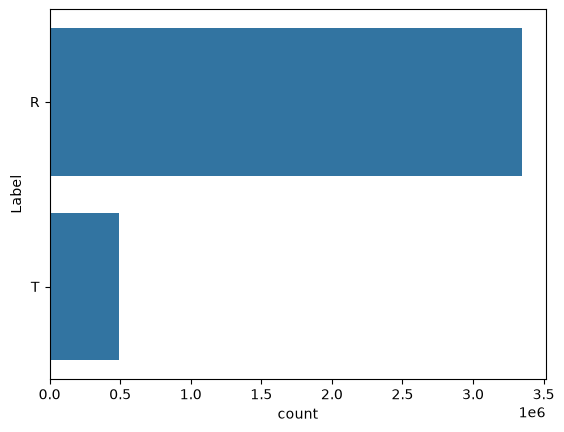

In [96]:
if RUN_RAW_EDA:
    sns.countplot(df_fuzzy["Label"])

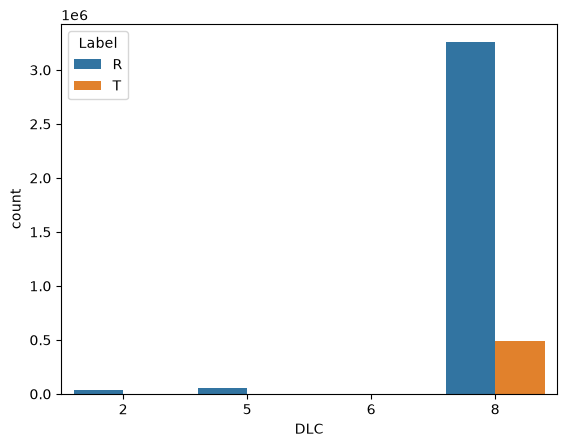

In [97]:
if RUN_RAW_EDA:
    sns.countplot(data=df_fuzzy, x="DLC", hue="Label")
    plt.show()

In [98]:
if RUN_RAW_EDA:
    display(df_fuzzy["Label"].value_counts(normalize=True) * 100)

Label
R    87.187681
T    12.812319
Name: proportion, dtype: float64

an imbalance class , this indicates that there are more normal cases than abnormal that means accuracy wouldnt be much of help. R=safe ,T=attacks

In [99]:
if RUN_RAW_EDA:
    display(df_fuzzy.columns)

Index(['Timestamp', 'CAN_ID', 'DLC', 'Byte0', 'Byte1', 'Byte2', 'Byte3',
       'Byte4', 'Byte5', 'Byte6', 'Byte7', 'Label'],
      dtype='str')

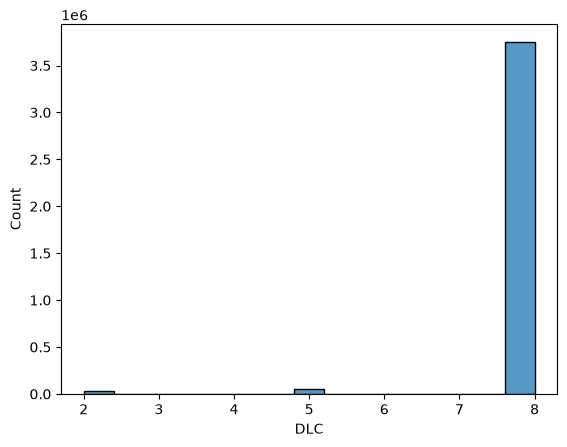

In [100]:
if RUN_RAW_EDA:
    sns.histplot(df_fuzzy,x="DLC",bins=15)

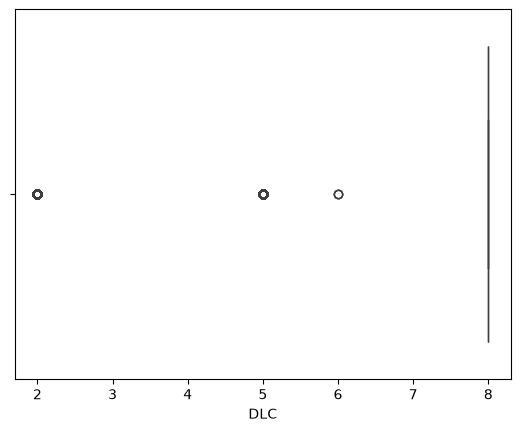

In [101]:
if RUN_RAW_EDA:
    sns.boxplot(data=df_fuzzy,x="DLC")

as we can observe that there are outliers however they are essintial and useful for determining the message sent.   

### for dos

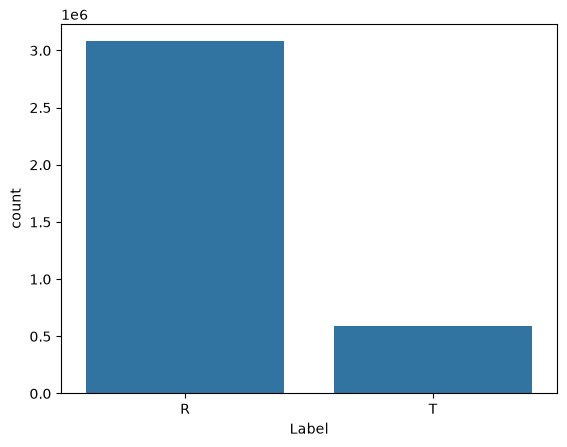

In [102]:
if RUN_RAW_EDA:
    sns.countplot(data=df_dos, x="Label")
    plt.show()

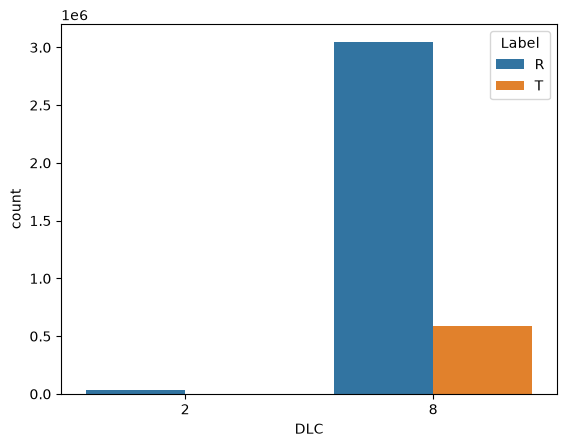

In [103]:
if RUN_RAW_EDA:
    sns.countplot(data=df_dos, x="DLC", hue="Label")
    plt.show()

In [104]:
if RUN_RAW_EDA:
    display(df_dos["Label"].value_counts(normalize=True) * 100)

Label
R    83.972785
T    16.027215
Name: proportion, dtype: float64

Similar estimation as fuzzy

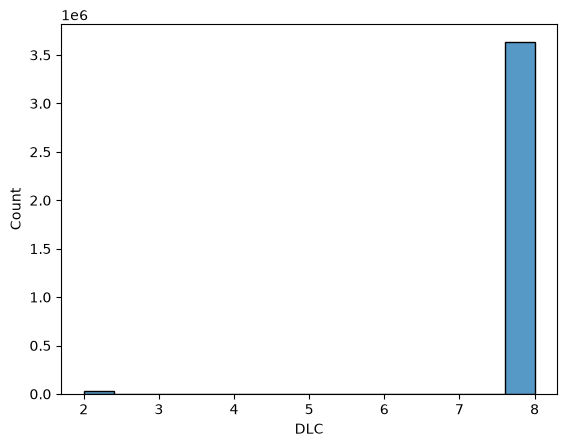

In [105]:
if RUN_RAW_EDA:
    sns.histplot(df_dos["DLC"],bins=15)

In [106]:
if RUN_RAW_EDA:
    display(df_dos["DLC"].value_counts())

DLC
8    3634583
2      31188
Name: count, dtype: int64

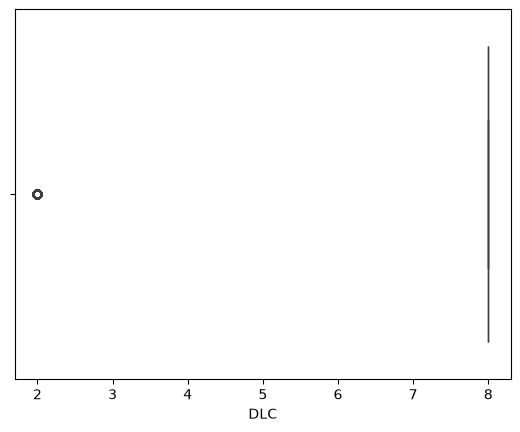

In [107]:
if RUN_RAW_EDA:
    sns.boxplot(data=df_dos, x="DLC")
    plt.show()

Similar estimation as fuzzy

### for rpm

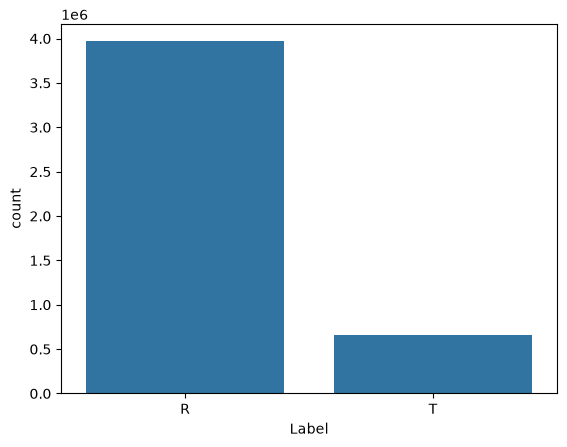

In [108]:
if RUN_RAW_EDA:
    sns.countplot(data=df_rpm, x="Label")
    plt.show()

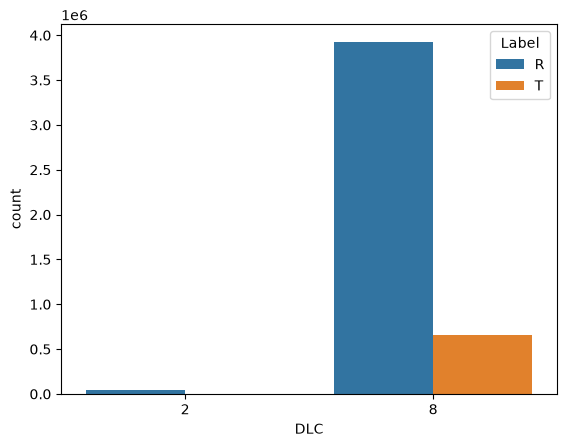

In [109]:
if RUN_RAW_EDA:
    sns.countplot(data=df_rpm, x="DLC", hue="Label")
    plt.show()

In [110]:
if RUN_RAW_EDA:
    display(df_rpm["Label"].value_counts(normalize=True) * 100)

Label
R    85.82996
T    14.17004
Name: proportion, dtype: float64

Similar estimation as fuzzy

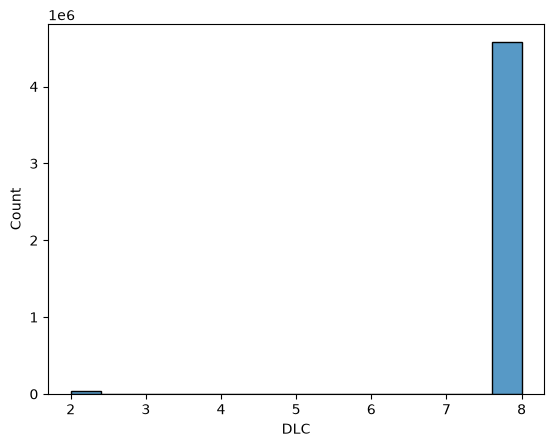

In [111]:
if RUN_RAW_EDA:
    sns.histplot(data=df_rpm, x="DLC", bins=15)
    plt.show()

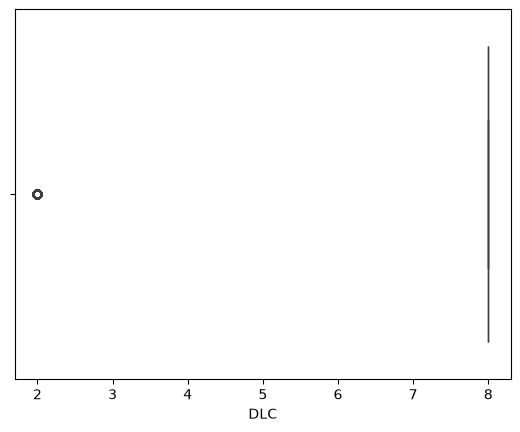

In [112]:
if RUN_RAW_EDA:
    sns.boxplot(data=df_rpm, x="DLC")
    plt.show()

Similar estimation as fuzzy

### for gear

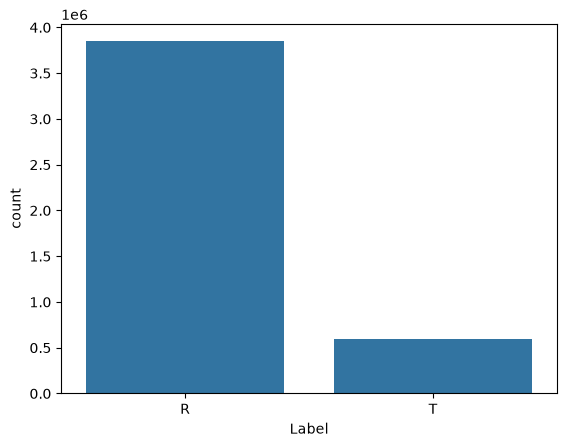

In [113]:
if RUN_RAW_EDA:
    sns.countplot(data=df_gear, x="Label")
    plt.show()

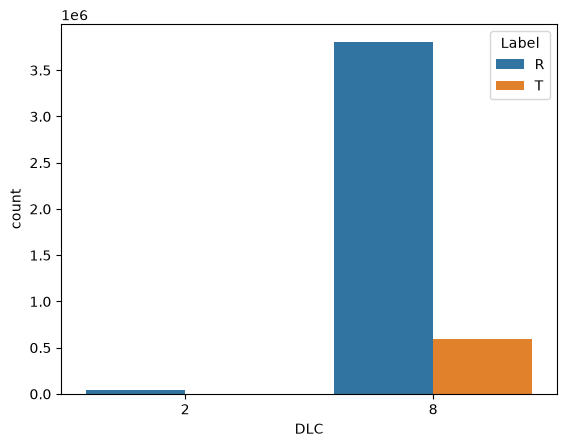

In [114]:
if RUN_RAW_EDA:
    sns.countplot(data=df_gear, x="DLC", hue="Label")
    plt.show()

In [115]:
if RUN_RAW_EDA:
    display(df_gear["Label"].value_counts(normalize=True) * 100)

Label
R    86.557891
T    13.442109
Name: proportion, dtype: float64

Similar estimation as fuzzy

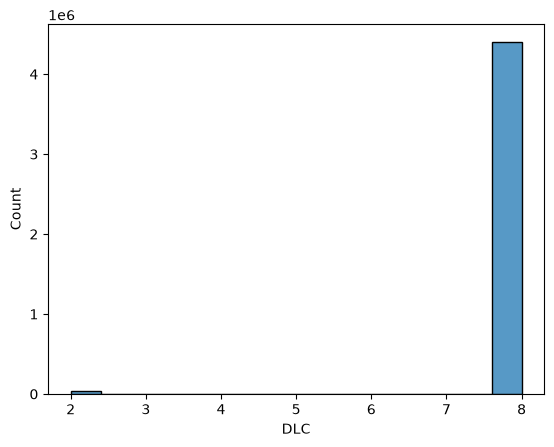

In [116]:
if RUN_RAW_EDA:
    sns.histplot(data=df_gear, x="DLC", bins=15)
    plt.show()

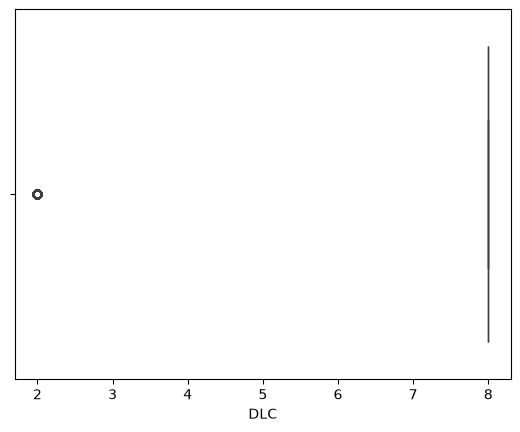

In [117]:
if RUN_RAW_EDA:
    sns.boxplot(data=df_gear, x="DLC")
    plt.show()

Similar estimation as fuzzy

##Bivariantes

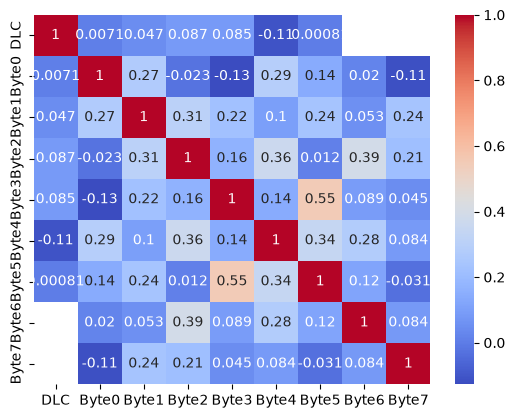

In [118]:
if RUN_RAW_EDA:
    sns.heatmap(
        df_fuzzy[["DLC"] + byte_columns].corr(),
        annot=True,
        cmap="coolwarm"
    )
    plt.show()

this wont tell much since each values correlation is a Byte however Most byte correlations are weak. Byte 4 is the most strongest out of the negative weak correlations

### for dos

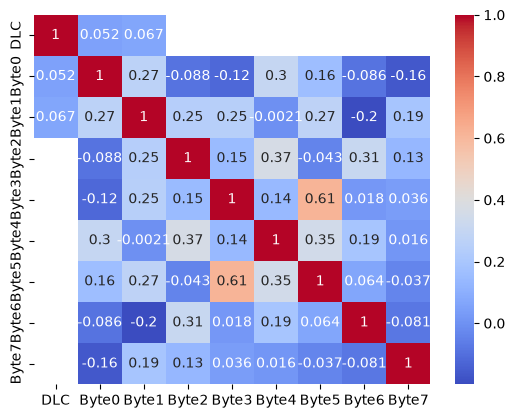

In [119]:
if RUN_RAW_EDA:
    sns.heatmap(df_dos[["DLC"] + byte_columns].corr(), annot=True, cmap="coolwarm")
    plt.show()

in this we see that DLC has really small correlations within Byte 0 and 1 meaning they are the most dominant bytes used for said attacks however we cannot be certain(requires further studying)

### for rpm

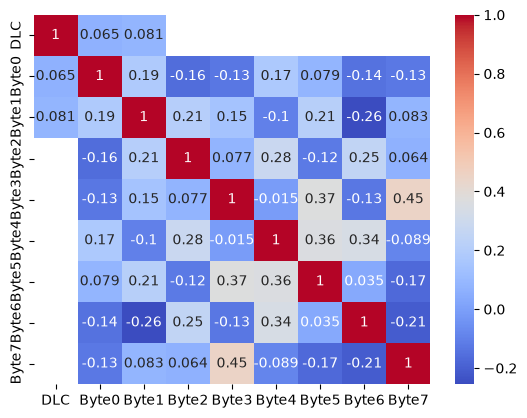

In [120]:
if RUN_RAW_EDA:
    sns.heatmap(df_rpm[["DLC"] + byte_columns].corr(), annot=True, cmap="coolwarm")
    plt.show()

byte 0 and 1 have a weak negative correlation around 0.065 and 0.081. No byte pair shows a very strong linear relationship.

### for gear

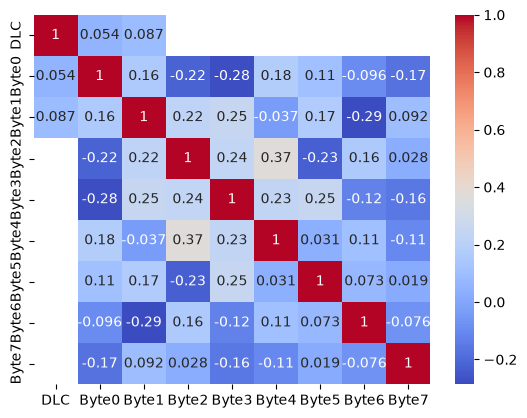

In [121]:
if RUN_RAW_EDA:
    sns.heatmap(df_gear[["DLC"] + byte_columns].corr(), annot=True, cmap="coolwarm")
    plt.show()

Byte 0 and 1 have the weak negative correlation around 0.054 and 0.087 meaning their values tend to move in opposite directions.

this suggest that Comparing heatmaps for normal and attack messages separately could reveal differences hidden when both groups are combined.

In [122]:
if RUN_RAW_EDA:
    comp= df_fuzzy.groupby("Label")[byte_columns].mean().T
    comp.columns.name = "Label"

    display(comp)

Label,R,T
Byte0,61.389985,127.375576
Byte1,44.859566,127.637741
Byte2,36.946443,127.484756
Byte3,64.068773,127.309590
Byte4,48.260603,127.362393
Byte5,69.020602,127.681824
Byte6,26.184431,127.356806
Byte7,48.507336,127.351622


we cant determine which byte is targeted hence all could be possible

In [123]:
if RUN_RAW_EDA:
    comp= df_dos.groupby("Label")[byte_columns].mean().T
    comp.columns.name = "Label"

    display(comp)

Label,R,T
Byte0,60.174958,0.0
Byte1,44.567195,0.0
Byte2,36.543299,0.0
Byte3,65.003091,0.0
Byte4,46.782640,0.0
Byte5,67.614578,0.0
Byte6,26.207661,0.0
Byte7,48.774627,0.0


no attacks are visible hence safe

In [124]:
if RUN_RAW_EDA:
    comp= df_rpm.groupby("Label")[byte_columns].mean().T
    comp.columns.name = "Label"

    display(comp)

Label,R,T
Byte0,58.844990,69.0
Byte1,42.826497,41.0
Byte2,35.565130,36.0
Byte3,64.304694,255.0
Byte4,56.114639,41.0
Byte5,66.705234,36.0
Byte6,26.446955,0.0
Byte7,45.409892,255.0


as we can see that byte 3 is the most attacks hence targeted since it has a great difference

In [125]:
if RUN_RAW_EDA:
    comp= df_gear.groupby("Label")[byte_columns].mean().T
    comp.columns.name = "Label"

    display(comp)

Label,R,T
Byte0,59.585722,1.0
Byte1,43.232545,69.0
Byte2,38.468194,96.0
Byte3,64.136892,255.0
Byte4,45.636446,107.0
Byte5,61.466407,0.0
Byte6,26.089265,0.0
Byte7,45.355902,0.0


though keep in mind that the outputs dont tell us for certain that the bytes are the target since its an avg and hypothisis only

In [126]:
if RUN_RAW_EDA:
    folder = RUN / "cleaned"
    os.makedirs(folder, exist_ok=True)

    datasets = {
        "normal": df,
        "fuzzy": df_fuzzy,
        "dos": df_dos,
        "rpm": df_rpm,
        "gear": df_gear
    }

    for name, data in datasets.items():
        assert data["Label"].isin(["R", "T"]).all(), f"Check Label in {name}"

        for position, column in enumerate(byte_columns):
            assert data[column].notna().eq(data["DLC"] > position).all(), (
                f"Check {column} and DLC in {name}"
            )

        data.to_parquet(f"{folder}/{name}.parquet", index=False)
        print(f"Saved {name}.parquet | {len(data):,} rows")

Saved normal.parquet | 988,871 rows


Saved fuzzy.parquet | 3,838,860 rows


Saved dos.parquet | 3,665,771 rows


Saved rpm.parquet | 4,621,702 rows


Saved gear.parquet | 4,443,142 rows


saving the datasets

###EDA Conclusion
From the EDA we can see that normal messages are more common than attacks in all four datasets.so accuracy alone wouldnt be enough to evaluate the model.
We checked missing values and duplicates.and how many bytes are used
We separated normal and abnormal messages using their labels so we have normal traffic as a baseline to compare attacks with. We compared their average byte values.
The heatmaps show mostly weak to moderate relationships between the bytes. The average comparisons showed differences between normal and attack messages that could help with detection, but they dont confirm which bytes are targeted.
most remaining messages in the attack datasets have DLC of 8 after cleaning. which indicates that the class is imbalnced.

---

# Part 2 — 02 — Data Preprocessing & Feature Engineering

**Original notebook:** `Preprocessing (1).ipynb`

In [127]:
# Release large raw tables before loading the cleaned export.
for variable in ('df', 'df_fuzzy', 'df_dos', 'df_rpm', 'df_gear',
                 'datasets', 'data', 'shifted', 'byte_count', 'valid', 'invalid'):
    globals().pop(variable, None)
gc.collect()
CLEANED = RUN / 'cleaned' if RUN_RAW_EDA else ARTIFACTS / 'cleaned'
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import joblib
import zipfile

##Uploading Dataset

In [128]:
normal = pd.read_parquet(CLEANED / 'normal.parquet')
dos = pd.read_parquet(CLEANED / 'dos.parquet')
fuzzy = pd.read_parquet(CLEANED / 'fuzzy.parquet')
gear = pd.read_parquet(CLEANED / 'gear.parquet')
rpm = pd.read_parquet(CLEANED / 'rpm.parquet')

files = {
    'normal': normal,
    'dos': dos,
    'fuzzy': fuzzy,
    'gear': gear,
    'rpm': rpm
}

for name, df in files.items():
  print(f"\n{name}: {df.shape}")
  print(df.columns.tolist())
  print(df.head())



normal: (988871, 12)
['Timestamp', 'CAN_ID', 'DLC', 'Byte0', 'Byte1', 'Byte2', 'Byte3', 'Byte4', 'Byte5', 'Byte6', 'Byte7', 'Label']
      Timestamp CAN_ID  DLC  Byte0  Byte1  Byte2  Byte3  Byte4  Byte5  Byte6  \
0  1.479121e+09   0350  8.0      5     40  132.0  102.0  109.0    0.0    0.0   
1  1.479121e+09   02c0  8.0     20      0    0.0    0.0    0.0    0.0    0.0   
2  1.479121e+09   0430  8.0      0      0    0.0    0.0    0.0    0.0    0.0   
3  1.479121e+09   04b1  8.0      0      0    0.0    0.0    0.0    0.0    0.0   
4  1.479121e+09   01f1  8.0      0      0    0.0    0.0    0.0    0.0    0.0   

   Byte7 Label  
0  162.0     R  
1    0.0     R  
2    0.0     R  
3    0.0     R  
4    0.0     R  

dos: (3665771, 12)
['Timestamp', 'CAN_ID', 'DLC', 'Byte0', 'Byte1', 'Byte2', 'Byte3', 'Byte4', 'Byte5', 'Byte6', 'Byte7', 'Label']
      Timestamp CAN_ID  DLC  Byte0  Byte1  Byte2  Byte3  Byte4  Byte5  Byte6  \
0  1.478198e+09   0316    8      5     33  104.0    9.0   33.0   33.0  

##Handling missing values

In [129]:
for name, df in files.items():
  print(f"\n{name} missing values:")
  print(df.isnull().sum())


normal missing values:
Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2        10129
Byte3        10129
Byte4        10129
Byte5        60735
Byte6        60735
Byte7        60735
Label            0
dtype: int64

dos missing values:
Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2        31188
Byte3        31188
Byte4        31188
Byte5        31188
Byte6        31188
Byte7        31188
Label            0
dtype: int64

fuzzy missing values:
Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2        34382
Byte3        34382
Byte4        34382
Byte5        87833
Byte6        87836
Byte7        87836
Label            0
dtype: int64

gear missing values:
Timestamp        0
CAN_ID           0
DLC              0
Byte0            0
Byte1            0
Byte2        40165
Byte3        40165
Byte4        40165
Byte5        40165
Byte6        401

In [130]:
byte_cols = [
    'Byte0', 'Byte1', 'Byte2', 'Byte3',
    'Byte4', 'Byte5', 'Byte6', 'Byte7'
]

for name, df in files.items():
  df[byte_cols] = df[byte_cols].fillna(0)
  print(name, df[byte_cols].isnull().sum().sum())


normal 0
dos 0
fuzzy 0
gear 0


rpm 0


Coverting CAN_ID from Hexadecimal to Decimal.

In [131]:
for name, df in files.items():
  print(f"\n{name}:")
  print(f"Data Type: {df['CAN_ID'].dtype}")
  print(f"Unique values: {df["CAN_ID"].nunique()}")




normal:
Data Type: str
Unique values: 27

dos:
Data Type: str
Unique values: 27

fuzzy:
Data Type: str
Unique values: 2048

gear:
Data Type: str


Unique values: 26

rpm:
Data Type: str
Unique values: 26


In [132]:
#Converting CAN_ID from Hexadecimal to Decimal numbers
for df in files.values():
  df["CAN_ID"] = df["CAN_ID"].apply(lambda x : int(str(x), 16))

normal["CAN_ID"].head()

0     848
1     704
2    1072
3    1201
4     497
Name: CAN_ID, dtype: int64

Features preparation

In [133]:
feat_cols = ["CAN_ID", "DLC"] + byte_cols #10 features not including time
X_files = {}

#define features for every file
for name, df in files.items():
  X_files[name] = df[feat_cols].copy()
  print(X_files[name].shape)



(988871, 10)
(3665771, 10)
(3838860, 10)
(4443142, 10)


(4621702, 10)


In [134]:
#Data splitting 80% training 20% validation (Training data)
x_train, x_val = train_test_split(X_files["normal"], test_size=0.2, shuffle=False)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)

Training: (791096, 10)
Validation: (197775, 10)


In [135]:
#scaling numeric features
scaler = MinMaxScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)

x_scaled_files = {}

for name in ['dos', 'fuzzy', 'gear', 'rpm']:
    x_scaled_files[name] = scaler.transform(X_files[name])

print("Train:", x_train_scaled.shape)
print("Validation:", x_val_scaled.shape)

for name, X in x_scaled_files.items():
    print(name, X.shape)

Train: (791096, 10)
Validation: (197775, 10)
dos (3665771, 10)
fuzzy (3838860, 10)
gear (4443142, 10)
rpm (4621702, 10)


In [136]:
# Save all datasets in one ZIP file
with zipfile.ZipFile('CAN_Bus_Preprocessed_Data.zip', 'w') as zipf:

    # Save Training
    train_df = pd.DataFrame(x_train_scaled, columns=feat_cols)
    train_df.to_parquet('train_scaled.parquet', index=False)
    zipf.write('train_scaled.parquet')

    # Save Validation
    val_df = pd.DataFrame(x_val_scaled, columns=feat_cols)
    val_df.to_parquet('validation_scaled.parquet', index=False)
    zipf.write('validation_scaled.parquet')

    # Save Testing datasets with Labels
    for name, X in x_scaled_files.items():
        test_df = pd.DataFrame(X, columns=feat_cols)
        test_df['Label'] = files[name]['Label'].values

        filename = f'{name}_test_scaled.parquet'
        test_df.to_parquet(filename, index=False)
        zipf.write(filename)
print('Archive saved in', RUN)

# The temporal stage starts from files, so release the plain feature copies.
del X_files, x_train, x_val, x_train_scaled, x_val_scaled
del x_scaled_files, train_df, val_df, test_df, X
gc.collect()

Archive saved in the run output folder.


2451

Trying Time features

In [137]:
#Adding Time features
for name, df in files.items():
  df.sort_values('Timestamp', inplace=True)

  #Time differnce between every message
  df['time_diff'] = df['Timestamp'].diff().fillna(0)

  #time difference between every message with the same CAN_ID
  df["can_id_time_diff"] = (
      df.groupby("CAN_ID")["Timestamp"].diff().fillna(0)
  )

/var/folders/21/bdm1tgpj7dz5ry2bjnk0b_7w0000gn/T/ipykernel_24599/877017083.py:3: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values('Timestamp', inplace=True)
/var/folders/21/bdm1tgpj7dz5ry2bjnk0b_7w0000gn/T/ipykernel_24599/877017083.py:3: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values('Timestamp', inplace=True)
/var/folders/21/bdm1tgpj7dz5ry2bjnk0b_7w0000gn/T/ipykernel_24599/877017083.py:3: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


/var/folders/21/bdm1tgpj7dz5ry2bjnk0b_7w0000gn/T/ipykernel_24599/877017083.py:3: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values('Timestamp', inplace=True)


In [138]:
#Adding new time features
feat_cols1 = ["CAN_ID", "DLC"] + byte_cols +["time_diff", "can_id_time_diff"] #12 features including time
X_files1 = {}

for name, df in files.items():
  X_files1[name] = df[feat_cols1].copy()
  print(X_files1[name].shape)

(988871, 12)
(3665771, 12)


(3838860, 12)
(4443142, 12)
(4621702, 12)


In [139]:
#Data splitting 80% training 20% validation (Training data)
x_train1, x_val1 = train_test_split(X_files1["normal"], test_size=0.2, shuffle=False)

print("Training:", x_train1.shape)
print("Validation:", x_val1.shape)

Training: (791096, 12)
Validation: (197775, 12)


In [140]:
scaler1 = MinMaxScaler()

x_train_scaled1 = scaler1.fit_transform(x_train1)
x_val_scaled1 = scaler1.transform(x_val1)

x_scaled_files1 = {}

for name in ['dos', 'fuzzy', 'gear', 'rpm']:
    x_scaled_files1[name] = scaler1.transform(X_files1[name])

print("Train:", x_train_scaled1.shape)
print("Validation:", x_val_scaled1.shape)

for name, X in x_scaled_files1.items():
    print(name, X.shape)

Train: (791096, 12)
Validation: (197775, 12)
dos (3665771, 12)
fuzzy (3838860, 12)
gear (4443142, 12)
rpm (4621702, 12)


In [141]:
# Save all datasets in one ZIP file
with zipfile.ZipFile('CAN_Bus_Preprocessed_Data_Time_Features.zip', 'w') as zipf:

    # Save Training
    train_df = pd.DataFrame(x_train_scaled1, columns=feat_cols1)
    train_df.to_parquet('train_scaled_time.parquet', index=False)
    zipf.write('train_scaled_time.parquet')

    # Save Validation
    val_df = pd.DataFrame(x_val_scaled1, columns=feat_cols1)
    val_df.to_parquet('validation_scaled_time.parquet', index=False)
    zipf.write('validation_scaled_time.parquet')

    # Save Testing datasets with Labels
    for name, X in x_scaled_files1.items():
        test_df = pd.DataFrame(X, columns=feat_cols1)
        test_df['Label'] = files[name]['Label'].values

        filename = f'{name}_test_scaled_time.parquet'
        test_df.to_parquet(filename, index=False)
        zipf.write(filename)

    # Save Scaler
    joblib.dump(scaler1, 'scaler_time.pkl')
    zipf.write('scaler_time.pkl')
print('Archive saved in', RUN)

Archive saved in the run output folder.


---

# Part 3 — 03 — Autoencoder Baseline

**Original notebook:** `Autoencoder_Baseline_time.ipynb`

# Autoencoder Baseline Model

- **baseline**: 10 features (CAN_ID, DLC, Byte0 to Byte7)
- **time**: 12 features (the same 10 plus `time_diff` and `can_id_time_diff`)

In [142]:
# Release full preprocessing tables before model inference.
for variable in ('normal', 'dos', 'fuzzy', 'gear', 'rpm', 'files', 'df',
                 'X_files', 'X_files1', 'x_train', 'x_val', 'x_train1', 'x_val1',
                 'x_train_scaled', 'x_val_scaled', 'x_train_scaled1', 'x_val_scaled1',
                 'x_scaled_files', 'x_scaled_files1', 'train_df', 'val_df', 'test_df', 'X'):
    globals().pop(variable, None)
gc.collect()
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

## 1. Load Data
- train_scaled / validation_scaled (10 features)
- train_scaled_time / validation_scaled_time (12 features)

In [143]:
with zipfile.ZipFile((RUN / "CAN_Bus_Preprocessed_Data.zip") if TRAIN_BASELINES else PLAIN_ZIP) as z:
    z.extract("train_scaled.parquet", "data")
    z.extract("validation_scaled.parquet", "data")

with zipfile.ZipFile((RUN / "CAN_Bus_Preprocessed_Data_Time_Features.zip") if TRAIN_BASELINES else TIME_ZIP) as z:
    z.extract("train_scaled_time.parquet", "data")
    z.extract("validation_scaled_time.parquet", "data")

train_df = {
    "baseline": pd.read_parquet("data/train_scaled.parquet"),
    "time": pd.read_parquet("data/train_scaled_time.parquet"),
}
val_df = {
    "baseline": pd.read_parquet("data/validation_scaled.parquet"),
    "time": pd.read_parquet("data/validation_scaled_time.parquet"),
}

x_train = {name: df.values.astype("float32") for name, df in train_df.items()}
x_val = {name: df.values.astype("float32") for name, df in val_df.items()}

for name in x_train:
    print(name, "train:", x_train[name].shape, "validation:", x_val[name].shape)

baseline train: (791096, 10) validation: (197775, 10)
time train: (791096, 12) validation: (197775, 12)


In [144]:
# both versions should hold the same rows in the same order,
# otherwise comparing them on the shared features is not fair
same_train = np.allclose(x_train["baseline"], x_train["time"][:, :10])
same_val = np.allclose(x_val["baseline"], x_val["time"][:, :10])
print("Same rows in train:", same_train)
print("Same rows in validation:", same_val)

Same rows in train: True
Same rows in validation: True


## 2. Build the model
- Encoder: n -> 8 -> 4 (bottleneck)
- Decoder: 4 -> 8 -> n
- ReLU in the hidden layers, sigmoid at the output because the data is scaled between 0 and 1
- Loss: MSE, optimizer: Adam

The input size is taken from the data, so the same function works for 10 and 12 features.

In [145]:
def build_model(n_features):
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(8, activation="relu"),
        layers.Dense(4, activation="relu"),
        layers.Dense(8, activation="relu"),
        layers.Dense(n_features, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="mse")
    return model


build_model(x_train["time"].shape[1]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │           108 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 288 (1.12 KB)

 Trainable params: 288 (1.12 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Training
Same settings for both: 20 epochs, batch size 256, seed 42 reset before each model.

In [146]:
if TRAIN_BASELINES:
    models = {}
    histories = {}

    for name in x_train:
        print(f"\nTraining the {name} model")
        tf.keras.utils.set_random_seed(42)
        model = build_model(x_train[name].shape[1])

        history = model.fit(
            x_train[name], x_train[name],
            validation_data=(x_val[name], x_val[name]),
            epochs=20,
            batch_size=256,
            verbose=2
        )

        models[name] = model
        histories[name] = history.history
else:
    models = {
        'baseline': keras.models.load_model(SAVED / 'baseline_autoencoder.keras', compile=False),
        'time': keras.models.load_model(SAVED / 'time_autoencoder.keras', compile=False)
    }
    histories = {}
    for name, model in models.items():
        expected_shape = (None, x_train[name].shape[1])
        if model.input_shape != expected_shape or model.output_shape != expected_shape:
            raise ValueError(f'{name}: saved model shape does not match the data.')
        print(f'Loaded saved {name} model: {model.input_shape} -> {model.output_shape}')


Loaded saved baseline model: (None, 10) -> (None, 10)
Loaded saved time model: (None, 12) -> (None, 12)


## 4. Draw Training / Validation Loss

In [147]:
if TRAIN_BASELINES:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for ax, name in zip(axes, histories):
        ax.plot(histories[name]["loss"], label="Training Loss")
        ax.plot(histories[name]["val_loss"], label="Validation Loss")
        ax.set_title(f"{name} autoencoder loss ({x_train[name].shape[1]} features)")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MSE")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig("loss_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

    for name, h in histories.items():
        print(f"{name}: last train loss {h['loss'][-1]:.6f}, last validation loss {h['val_loss'][-1]:.6f}")
else:
    print('Training history plot skipped because saved models were loaded.')

Training history plot skipped because saved models were loaded.


## 5. Calculate Reconstruction Error

In [148]:
train_errors = {}
val_errors = {}
feature_errors = {}

for name, model in models.items():
    train_pred = model.predict(x_train[name], batch_size=4096, verbose=0)
    val_pred = model.predict(x_val[name], batch_size=4096, verbose=0)

    train_errors[name] = np.mean((x_train[name] - train_pred) ** 2, axis=1)
    val_errors[name] = np.mean((x_val[name] - val_pred) ** 2, axis=1)

    # error of every feature on the validation set
    feature_errors[name] = np.mean((x_val[name] - val_pred) ** 2, axis=0)

    print(f"\n{name}")
    print("Train error mean:", round(train_errors[name].mean(), 6))
    print("Validation error mean:", round(val_errors[name].mean(), 6))
    print("Validation error max:", round(val_errors[name].max(), 6))


baseline
Train error mean: 0.008136
Validation error mean: 0.008027
Validation error max: 0.140589



time
Train error mean: 0.011122
Validation error mean: 0.011402
Validation error max: 0.123525


### Error distribution (train vs validation)
If the two distributions look the same, the model rebuilds normal messages it did not see as well as the ones it trained on.

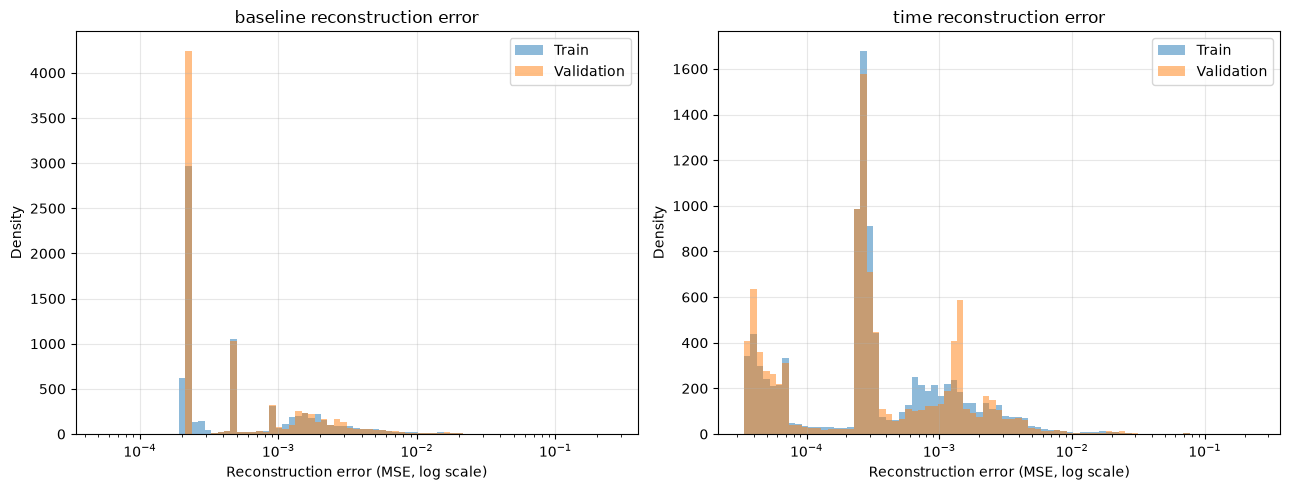

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, models):
    all_errors = np.concatenate([train_errors[name], val_errors[name]])
    low = all_errors[all_errors > 0].min()
    bins = np.logspace(np.log10(low), np.log10(all_errors.max()), 80)
    ax.hist(train_errors[name], bins=bins, alpha=0.5, density=True, label="Train")
    ax.hist(val_errors[name], bins=bins, alpha=0.5, density=True, label="Validation")
    ax.set_xscale("log")
    ax.set_title(f"{name} reconstruction error")
    ax.set_xlabel("Reconstruction error (MSE, log scale)")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Error per feature
The total MSE of the two models can not be compared directly (10 columns vs 12 columns),
so we compare them on the 10 features they share.

In [150]:
per_feature = pd.DataFrame({
    "baseline": pd.Series(feature_errors["baseline"], index=train_df["baseline"].columns),
    "time": pd.Series(feature_errors["time"], index=train_df["time"].columns),
}).reindex(train_df["time"].columns)
print(per_feature.round(6))

shared = train_df["baseline"].columns
print("\nValidation error on the 10 shared features")
print("baseline:", round(per_feature.loc[shared, "baseline"].mean(), 6))
print("time:", round(per_feature.loc[shared, "time"].mean(), 6))

                  baseline      time
CAN_ID            0.007692  0.007982
DLC               0.006074  0.013944
Byte0             0.007310  0.004138
Byte1             0.011354  0.010799
Byte2             0.011999  0.007542
Byte3             0.011472  0.006460
Byte4             0.009258  0.018252
Byte5             0.005953  0.005153
Byte6             0.002267  0.045901
Byte7             0.006888  0.010781
time_diff              NaN  0.005648
can_id_time_diff       NaN  0.000201

Validation error on the 10 shared features
baseline: 0.008027
time: 0.013095


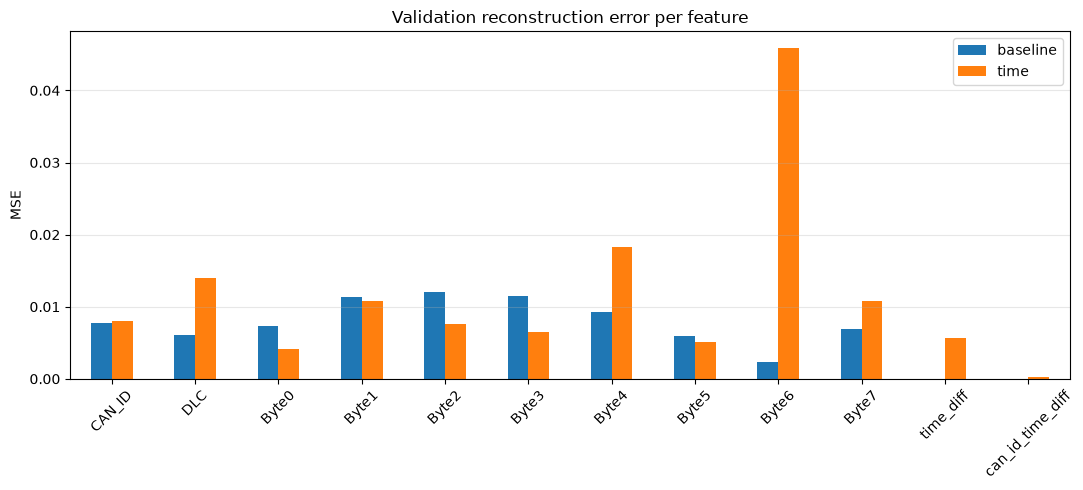

In [151]:
per_feature.plot(kind="bar", figsize=(11, 5))
plt.title("Validation reconstruction error per feature")
plt.ylabel("MSE")
plt.xticks(rotation=45)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("error_per_feature.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Save Result

In [152]:
for name in models:
    if TRAIN_BASELINES:
        models[name].save(f"{name}_autoencoder.keras")
        pd.DataFrame(histories[name]).to_csv(f"{name}_history.csv", index_label="epoch")
    pd.DataFrame({"error": train_errors[name]}).to_csv(f"{name}_train_errors.csv", index=False)
    pd.DataFrame({"error": val_errors[name]}).to_csv(f"{name}_validation_errors.csv", index=False)

per_feature.to_csv("error_per_feature.csv", index_label="feature")
print("Saved")

Saved


## 7. Notes
- Baseline (10 features): training and validation loss went down together and stayed close, so the model is not overfitting. Validation error (0.0080) is almost the same as train error (0.0081).
- Time model (12 features): also no overfitting, train loss 0.0111 and validation loss 0.0114, and the train and validation error distributions overlap.
- On the 10 features both models share, the time model has a higher error (0.0131 vs 0.0080). Most of it comes from Byte6 (0.046 vs 0.002), Byte4 and DLC. The bottleneck is still 4 neurons but now it has to hold 12 features, so the model gives up some of the byte information.
- The time model loss was still going down at epoch 20, so it did not fully converge yet. More epochs or a bigger bottleneck can be tried in the tuning step.
- can_id_time_diff has a very small error (0.0002) because after MinMax scaling most of its values are close to 0, so the model learns it easily.
- A lower error on normal data does not mean better attack detection. Time features may help with attacks that change message timing like DoS, so the final choice between the two versions should come from the evaluation on the attack files.

## Archived training curve from Person 3
Baseline training was disabled in the integrated run. This cell displays the original saved loss figure from Person 3’s executed notebook.

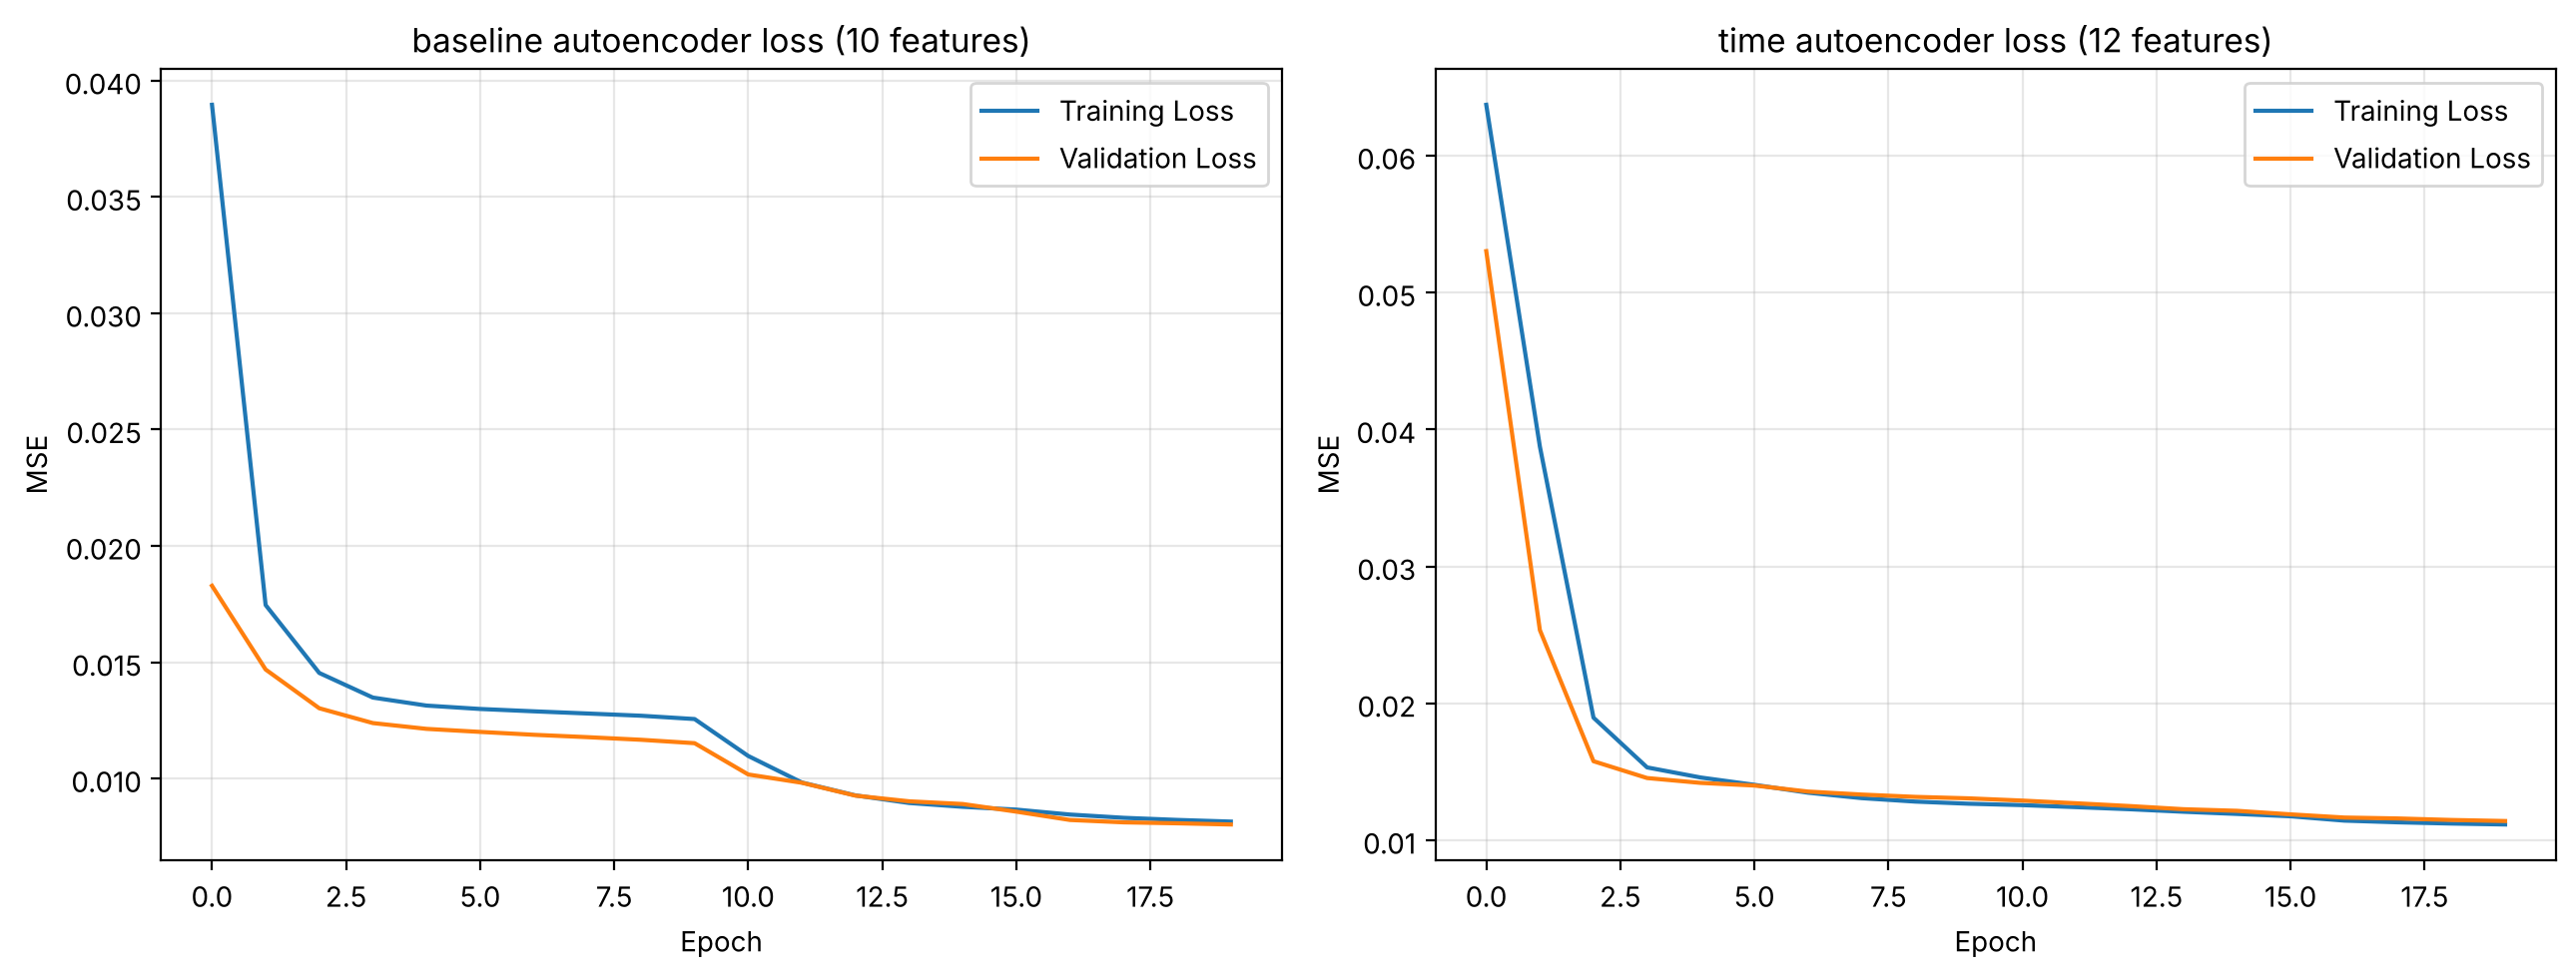

In [1]:
from pathlib import Path
from IPython.display import Image, display
import base64
import json

submission = Path(globals().get('PROJECT', Path.cwd()))
baseline_notebook = json.loads(
    (submission / 'notebooks/03_Autoencoder_Baseline.ipynb').read_text()
)
for output in baseline_notebook['cells'][10]['outputs']:
    image = output.get('data', {}).get('image/png')
    if image:
        if isinstance(image, list):
            image = ''.join(image)
        display(Image(data=base64.b64decode(image)))

---

# Part 4 — 04 — Hyperparameter Tuning (Temporal v2)

**Original notebook:** `04_Tuning_Time_v2.ipynb`

# Hyperparameter Tuning Task: GhostShield Time Autoencoder

In [153]:
# Keras is pinned in requirements-executed.txt.

## Import Libraries

In [154]:
import os, json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import matplotlib.pyplot as plt

SEED = 42
tf.keras.utils.set_random_seed(SEED)

for folder in ["models", "results/plots", "configs"]:
    os.makedirs(folder, exist_ok=True)

## Load the Dataset

In [155]:
x_train = pd.read_parquet((RUN / "train_scaled_time.parquet") if TRAIN_BASELINES else (SCALED_TIME / "train_scaled_time.parquet")).values.astype("float32")
x_val = pd.read_parquet((RUN / "validation_scaled_time.parquet") if TRAIN_BASELINES else (SCALED_TIME / "validation_scaled_time.parquet")).values.astype("float32")

print(x_train.shape, x_val.shape)

(791096, 12) (197775, 12)


## Task 1: Baseline Model


In [156]:
baseline_model = keras.models.load_model((RUN if TRAIN_BASELINES else SAVED) / "time_autoencoder.keras", compile=False)

def val_loss(model):
    pred = model.predict(x_val, batch_size=4096, verbose=0)
    return float(np.mean((x_val - pred) ** 2))

baseline_loss = val_loss(baseline_model)
print("Baseline val_loss:", round(baseline_loss, 6))

Baseline val_loss: 0.011402


## Build the Model


In [157]:
def build_model(hidden=[8, 4, 8], lr=0.001, l2=0.0, dropout=0.0):
    tf.keras.utils.set_random_seed(SEED)
    reg = regularizers.l2(l2)

    model = keras.Sequential([layers.Input(shape=(12,))])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0 and units != min(hidden):
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(12, activation="sigmoid"))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return model

# Check: our default model must have the same size as the baseline (288 parameters)
print("Baseline params:", baseline_model.count_params(), "| our params:", build_model().count_params())

Baseline params: 288 | our params: 288


## Early Stopping
Stops training when val_loss stops improving, and keeps the best epoch.
- `patience=10`: gives the model time to get past slow phases before stopping.
- `min_delta=1e-5`: small enough that slow but real improvements still count.

In [158]:
# Early Stopping: stop when val_loss stops improving, and keep the best epoch.
# A function, because every experiment needs a fresh copy.
def early_stop():
    return keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        min_delta=0.00001,
        restore_best_weights=True,
    )

results = []     # one row per experiment -> final results table
models = {}      # trained model of each experiment
histories = {}   # training curve of each experiment (for plots)

## Task 2: Reproduce the Baseline + Add Early Stopping
- **E01:** same as the baseline (20 epochs, no Early Stopping). Should give about the same val_loss as the baseline.
- **E02:** only change: Early Stopping with up to 100 epochs.

In [159]:
if RUN_TUNING:
    #E01:
    # Goal: prove our code gives the same result as the baseline

    model = build_model()
    h01 = model.fit(x_train, x_train,                              #  train: input = target (autoencoder)
                    validation_data=(x_val, x_val),
                    epochs=20, batch_size=256, verbose=0)
    loss = val_loss(model)

    results.append({"ID": "E01", "Architecture": "8-4-8", "LR": 0.001, "Batch": 256,
                    "Regularization": "None", "Val Loss": loss, "Epochs": 20,
                    "Params": model.count_params(), "Notes": "Reproduce baseline"})
    models["E01"] = model
    histories["E01"] = h01.history
    print("E01 val_loss:", round(loss, 6))


    #E02:
    # Hypothesis: val_loss was still falling at epoch 20, so longer training will lower it

    model = build_model()
    h02 = model.fit(x_train, x_train,
                    validation_data=(x_val, x_val),
                    epochs=200, batch_size=256,
                    callbacks=[early_stop()], verbose=0)
    loss = val_loss(model)
    epochs_run = len(h02.history["loss"])                          # how many epochs before it stopped

    # 4) record the result
    results.append({"ID": "E02", "Architecture": "8-4-8", "LR": 0.001, "Batch": 256,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": "val_loss still falling at epoch 20 -> train longer"})
    models["E02"] = model
    histories["E02"] = h02.history
    print("E02 val_loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")
else:
    print('Tuning experiments and export skipped. No model was retrained.')

Tuning experiments and export skipped. No model was retrained.


## Task 3: Tune Learning Rate
The baseline used 0.001. Try 3× bigger (0.003) and 3× smaller (0.0003).

In [160]:
if RUN_TUNING:
    lr_results = {0.001: results[-1]["Val Loss"]}      # results[-1] = last row added = E02

    # Each experiment: (experiment name, learning rate to try, hypothesis)
    lr_experiments = [
        ("E03",  0.003,  "Bigger LR: may learn faster"),
        ("E04",  0.0003, "Smaller LR: slower but smoother learning"),
        ("E04b", 0.002,  "Between 0.001 and 0.003: faster but still stable"),
    ]

    for exp_id, lr, note in lr_experiments:
        print(f"\nTraining {exp_id} with learning rate = {lr}")

        model = build_model(lr=lr)
        h = model.fit(x_train, x_train,
                      validation_data=(x_val, x_val),
                      epochs=200, batch_size=256,
                      callbacks=[early_stop()], verbose=0)
        loss = val_loss(model)
        epochs_run = len(h.history["loss"])

        #record the result
        results.append({"ID": exp_id, "Architecture": "8-4-8", "LR": lr, "Batch": 256,
                        "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                        "Params": model.count_params(), "Notes": note})
        models[exp_id] = model
        histories[exp_id] = h.history
        lr_results[lr] = loss                                      # keep for choosing the best LR

        print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

    # Choose the learning rate with the lowest val loss -> used in all next tasks
    best_lr = min(lr_results, key=lr_results.get)
    print("\nAll LR results:", lr_results)
    print("Best learning rate:", best_lr)

## Task 4: Tune Batch Size
The baseline used 256. Try half (128) and double (512), with the best learning rate.

In [161]:
if RUN_TUNING:
    # Batch 256 with the best LR was already trained in Task 3, so we reuse its result
    batch_results = {256: lr_results[best_lr]}

    # Each experiment: (experiment name, batch size to try, hypothesis)
    batch_experiments = [
        ("E05", 128, "Smaller batch: more weight updates per epoch, may learn finer details"),
        ("E06", 512, "Bigger batch: faster and smoother training, maybe similar loss"),
    ]

    for exp_id, batch, note in batch_experiments:
        print(f"\nTraining {exp_id} with batch size = {batch}")

        model = build_model(lr=best_lr)
        h = model.fit(x_train, x_train,
                      validation_data=(x_val, x_val),
                      epochs=200, batch_size=batch,
                      callbacks=[early_stop()], verbose=0)
        loss = val_loss(model)
        epochs_run = len(h.history["loss"])

        # record the result
        results.append({"ID": exp_id, "Architecture": "8-4-8", "LR": best_lr, "Batch": batch,
                        "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                        "Params": model.count_params(), "Notes": note})
        models[exp_id] = model
        histories[exp_id] = h.history
        batch_results[batch] = loss                         # keep for choosing the best batch

        print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

    # Choose the batch size with the lowest val loss -> used in all next tasks
    best_batch = min(batch_results, key=batch_results.get)
    print("\nAll batch results:", batch_results)
    print("Best batch size:", best_batch)

## Task 5: Tune Layer Sizes
Baseline: 8-4-8. The middle layer (bottleneck) stays **4** in all experiments; only the width and depth change.
If the middle layer gets close to 12 (the number of features), the model just copies the input and cannot detect attacks.

In [162]:
if RUN_TUNING:
    # 8-4-8 with the best LR and batch was already trained, so we reuse its result
    arch_results = {"8-4-8": batch_results[best_batch]}

    # Each experiment: (experiment name, hidden layers, hypothesis)
    arch_experiments = [
        ("E07", [6, 4, 6],         "Narrower: 8-4-8 may be bigger than needed"),
        ("E08", [16, 4, 16],       "Wider: more units may capture more patterns"),
        ("E09", [16, 8, 4, 8, 16], "Deeper: more gradual compression may help"),
    ]

    for exp_id, hidden, note in arch_experiments:
        name = "-".join(map(str, hidden))                  # [16, 4, 16] -> "16-4-16"
        print(f"\nTraining {exp_id} with layers = {name}")

        model = build_model(hidden=hidden, lr=best_lr)     # only the layers change
        h = model.fit(x_train, x_train,
                      validation_data=(x_val, x_val),
                      epochs=200, batch_size=best_batch,
                      callbacks=[early_stop()], verbose=0)
        loss = val_loss(model)
        epochs_run = len(h.history["loss"])

        # record the result
        results.append({"ID": exp_id, "Architecture": name, "LR": best_lr, "Batch": best_batch,
                        "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                        "Params": model.count_params(), "Notes": note})
        models[exp_id] = model
        histories[exp_id] = h.history
        arch_results[name] = loss                          # keep for choosing the best layers

        print("Val loss:", round(loss, 6), "| params:", model.count_params(), "| stopped after", epochs_run, "epochs")

    # Choose the layers with the lowest val loss -> used in the next task
    best_arch = min(arch_results, key=arch_results.get)
    best_hidden = [int(u) for u in best_arch.split("-")]  # "16-4-16" -> [16, 4, 16]
    print("\nAll layer results:", arch_results)
    print("Best layers:", best_arch)

## Task 5b: Re-check the LR on the Best Layers
The best LR was chosen on 8-4-8, so the best layers may need a different one.
We try the 2nd best LR from Task 3 on the best layers.


In [163]:
if RUN_TUNING:
    # Task 5b: re-check the LR on the best layers
    # The best LR was chosen on 8-4-8, so the best layers may need a different one
    lr_recheck = {best_lr: arch_results[best_arch]}
    second_lr = sorted(lr_results, key=lr_results.get)[1]     # 2nd best LR from Task 3

    print(f"Training E09b with layers = {best_arch} and learning rate = {second_lr}")
    model = build_model(hidden=best_hidden, lr=second_lr)
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=200, batch_size=best_batch,
                  callbacks=[early_stop()], verbose=0)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    results.append({"ID": "E09b", "Architecture": best_arch, "LR": second_lr, "Batch": best_batch,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": "Re-check LR on the best layers"})
    models["E09b"] = model
    histories["E09b"] = h.history
    lr_recheck[second_lr] = loss

    print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

    # Keep the better LR for the best layers -> used in Task 6
    best_lr = min(lr_recheck, key=lr_recheck.get)
    best_before_reg = lr_recheck[best_lr]
    print("\nLR results on", best_arch, ":", lr_recheck)
    print("Best learning rate:", best_lr)

## Task 6: L2 and Dropout
Applied to the best model so far (best layers, best LR, best batch).

**L2 values** come from the baseline model: L2 adds λ × (sum of squared weights) to the loss.
We pick λ so this extra penalty is about **1%** and **10%** of the baseline loss.

In [164]:
# Sum of squared weights in the baseline model
sum_sq = 0
for layer in baseline_model.layers:
    weights = layer.get_weights()[0]
    sum_sq += np.sum(weights ** 2)

# L2 so the penalty ≈ 1% and 10% of the baseline loss
l2_small = float(f"{0.01 * baseline_loss / sum_sq:.0e}")
l2_large = float(f"{0.10 * baseline_loss / sum_sq:.0e}")

print("L2 values to try:", np.format_float_positional(l2_small), np.format_float_positional(l2_large))

L2 values to try: 0.0000002 0.000002


In [165]:
if RUN_TUNING:
    reg_experiments = [
        ("E10", l2_small, 0.0,  "Light L2: may help generalization"),
        ("E11", l2_large, 0.0,  "Stronger L2: may underfit"),
        ("E12", 0.0,      0.1,  "Dropout 0.1: small network, probably no help"),
        ("E13", 0.0,      0.05, "Smaller dropout: may hurt less"),
    ]

    for exp_id, l2, dropout, note in reg_experiments:
        if l2 > 0:
            reg_name = f"ES + L2 {np.format_float_positional(l2)}"
        else:
            reg_name = f"ES + Dropout {dropout}"
        print(f"\nTraining {exp_id} with {reg_name}")

        model = build_model(hidden=best_hidden, lr=best_lr, l2=l2, dropout=dropout)
        h = model.fit(x_train, x_train,
                      validation_data=(x_val, x_val),
                      epochs=200, batch_size=best_batch,
                      callbacks=[early_stop()], verbose=0)
        loss = val_loss(model)
        epochs_run = len(h.history["loss"])

        results.append({"ID": exp_id, "Architecture": best_arch, "LR": best_lr, "Batch": best_batch,
                        "Regularization": reg_name, "Val Loss": loss, "Epochs": epochs_run,
                        "Params": model.count_params(), "Notes": note})
        models[exp_id] = model
        histories[exp_id] = h.history

        print("Val loss:", round(loss, 6), "| before:", round(best_before_reg, 6),
              "| better?", loss < best_before_reg)

## Final Comparison

In [166]:
if RUN_TUNING:
    results_df = pd.DataFrame(results)
    results_df.to_csv("results/tuning_results.csv", index=False)
    display(results_df)

    # Selection rule: lowest val loss, but simplest model if within 2%
    lowest = results_df["Val Loss"].min()
    close = results_df[results_df["Val Loss"] <= lowest * 1.02]
    best = close.sort_values(["Params", "Val Loss"]).iloc[0]

    print("Lowest val_loss:", round(lowest, 6))
    print("Within 2%:", list(close["ID"]))
    print("Chosen (simplest):", best["ID"], "| params:", best["Params"])

    print("\nBaseline val_loss:", round(baseline_loss, 6))
    print("Best model:", best["ID"], "| val_loss:", round(best["Val Loss"], 6))
    print("Difference:", round(baseline_loss - best["Val Loss"], 6))
    print(f"Improvement: {(baseline_loss - best['Val Loss']) / baseline_loss * 100:.1f}%")

## Save the Best Model

In [167]:
if RUN_TUNING:
    best_model = models[best["ID"]]
    best_model.save("models/best_ae.keras")

    best_config = {
        "experiment_id": best["ID"],
        "architecture": best["Architecture"],
        "learning_rate": float(best["LR"]),
        "batch_size": int(best["Batch"]),
        "regularization": best["Regularization"],
        "early_stopping": {"monitor": "val_loss", "patience": 10, "min_delta": 0.00001},
        "epochs_run": int(best["Epochs"]),
        "val_loss": float(best["Val Loss"]),
        "baseline_val_loss": baseline_loss,
        "selection_rule": "lowest val_loss; simplest model if within 2%",
        "seed": SEED,
    }
    with open("configs/best_config.json", "w") as f:
        json.dump(best_config, f, indent=2)

    print(best_config)

    # Check: the saved file opens and gives the same val_loss
    reloaded = keras.models.load_model("models/best_ae.keras")
    print("Reloaded val_loss:", round(val_loss(reloaded), 6))

## Plots

In [168]:
if RUN_TUNING:
    # 1) Val loss of every experiment (chosen model in red)
    colors = ["red" if exp_id == best["ID"] else "steelblue" for exp_id in results_df["ID"]]

    plt.figure(figsize=(9, 5))
    plt.barh(results_df["ID"], results_df["Val Loss"], color=colors)
    plt.axvline(baseline_loss, color="gray", linestyle="--", label="Baseline")
    plt.xlabel("Validation loss (lower is better)")
    plt.title("Val loss per experiment")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.savefig("results/plots/tuning_val_loss.png", dpi=150, bbox_inches="tight")
    plt.show()

In [169]:
if RUN_TUNING:
    # 2) Overfitting check: train loss vs val loss of the best model
    h = histories[best["ID"]]

    plt.figure(figsize=(8, 5))
    plt.plot(h["loss"], label="Train loss")
    plt.plot(h["val_loss"], label="Val loss")
    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title(f"Overfitting check: {best['ID']}")
    plt.legend()
    plt.savefig("results/plots/overfitting_check.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Loss on the full train set vs val set (final weights)
    train_loss = float(np.mean((x_train - best_model.predict(x_train, batch_size=4096, verbose=0)) ** 2))
    val_loss_best = val_loss(best_model)
    gap = (val_loss_best - train_loss) / train_loss * 100

    print("Train loss:", round(train_loss, 6))
    print("Val loss:  ", round(val_loss_best, 6))
    print(f"Gap: {gap:.1f}%")

    if gap < 5:
        print("No overfitting: train and val loss are close")
    else:
        print("Possible overfitting: val loss is much higher than train loss")

In [170]:
if RUN_TUNING:
    # 3) Val loss curve: baseline (E01) vs best model
    plt.figure(figsize=(8, 5))
    plt.plot(histories["E01"]["val_loss"], label="Baseline (E01)")
    plt.plot(histories[best["ID"]]["val_loss"], label=f"Best ({best['ID']})")
    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Val loss (log scale)")
    plt.title("Baseline vs Tuned training")
    plt.legend()
    plt.savefig("results/plots/baseline_vs_tuned_loss.png", dpi=150, bbox_inches="tight")
    plt.show()

## Reflection Questions
*(Answer after running.)*
1. Which hyperparameter had the biggest impact on val loss?
*
2. Did Early Stopping help? After how many epochs did it stop?
*
3. Did bigger or deeper layers always improve the result?
*
4. Did L2 or Dropout help? Why / why not?
*
5. Which model would you choose, and why?
*

## Archived results from Person 4
The training branches above were disabled in the integrated run. This cell displays the 15 real experiments and figures from the previously executed temporal tuning notebook.

,ID,Architecture,LR,Batch,Regularization,Val Loss,Epochs,Params
0,E01,8-4-8,0.0010,256,None,0.011392,20,288
1,E02,8-4-8,0.0010,256,EarlyStopping,0.008791,147,288
2,E03,8-4-8,0.0030,256,EarlyStopping,0.018337,33,288
3,E04,8-4-8,0.0003,256,EarlyStopping,0.009857,132,288
4,E04b,8-4-8,0.0020,256,EarlyStopping,0.011000,29,288
5,E05,8-4-8,0.0010,128,EarlyStopping,0.011049,58,288
6,E06,8-4-8,0.0010,512,EarlyStopping,0.007339,67,288
7,E07,6-4-6,0.0010,512,EarlyStopping,0.011375,49,220
8,E08,16-4-16,0.0010,512,EarlyStopping,0.002949,137,560
9,E09,16-8-4-8-16,0.0010,512,EarlyStopping,0.001344,184,768


Selected experiment: E09
Baseline validation MSE: 0.011401691474020481
Tuned validation MSE: 0.0013439235044643283


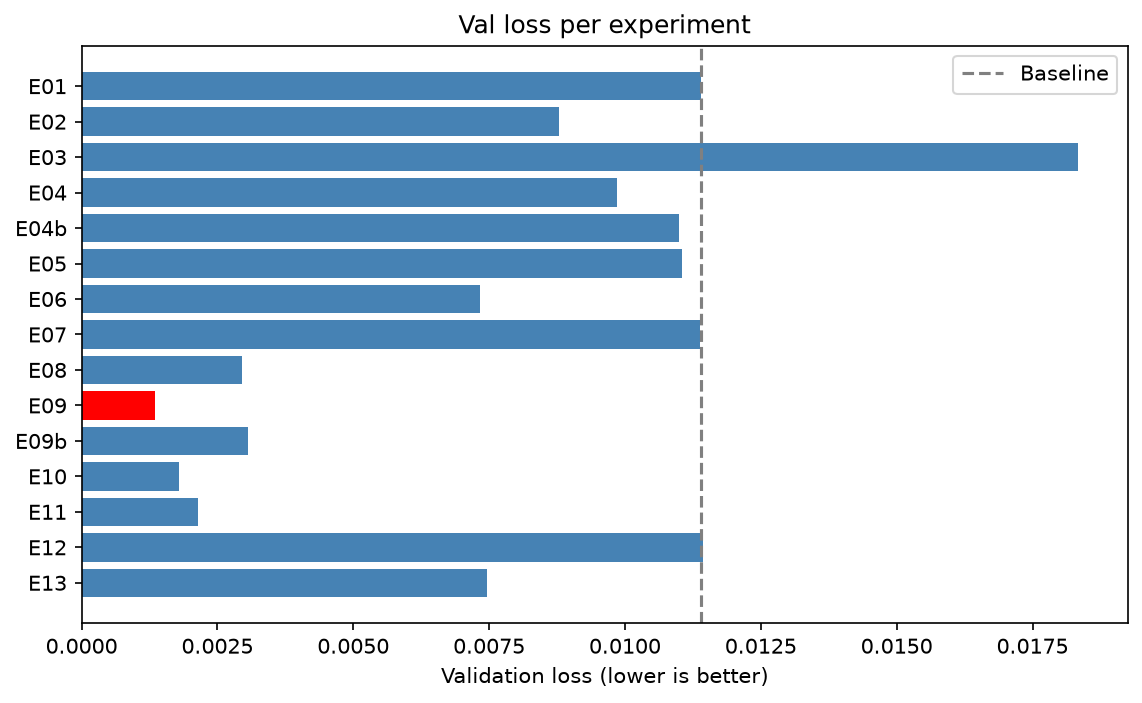

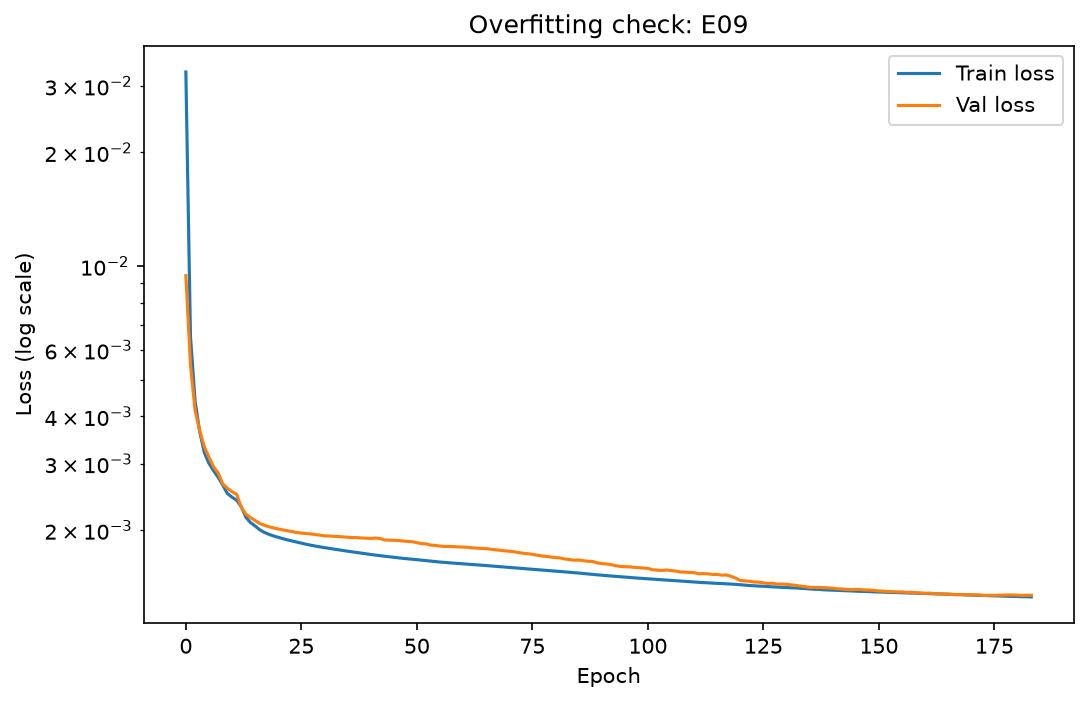

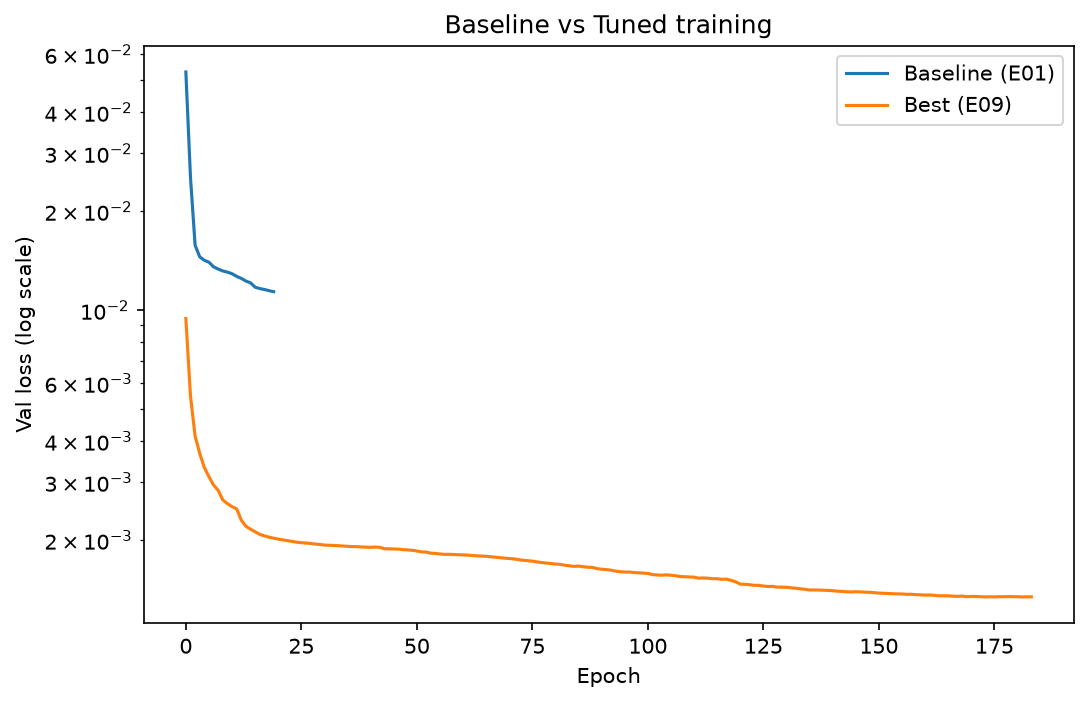

In [2]:
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
import json

submission = Path(globals().get('PROJECT', Path.cwd()))
tuning = submission / 'results/tuning'
experiments = pd.read_csv(tuning / 'tuning_results.csv', keep_default_na=False)
assert len(experiments) == 15
display(experiments.drop(columns='Notes'))
selected = json.loads((tuning / 'best_config.json').read_text())
print('Selected experiment:', selected['experiment_id'])
print('Baseline validation MSE:', selected['baseline_val_loss'])
print('Tuned validation MSE:', selected['val_loss'])
for name in ('tuning_val_loss.png', 'overfitting_check.png', 'baseline_vs_tuned_loss.png'):
    display(Image(filename=str(tuning / 'plots' / name)))

# Part 5 — Tuned model evaluation

In [171]:
# Release model diagnostics and training arrays before evaluating 16.6M messages.
for name in ('x_train', 'x_val', 'train_df', 'val_df', 'models', 'histories',
             'train_errors', 'val_errors', 'feature_errors', 'train_pred',
             'val_pred', 'all_errors', 'baseline_model', 'best_model', 'reloaded'):
    globals().pop(name, None)
gc.collect()


12712

## 1. Import Libraries
Use Keras for inference, PyArrow for batches, and scikit-learn for evaluation.

In [172]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
from tensorflow import keras
import pyarrow.parquet as pq

## 2. Load Model and Data
Use the original scaled files from the project directory.

In [173]:
MODEL = TUNED_MODEL
VALIDATION = SCALED_TIME / 'validation_scaled_time.parquet'
TESTS = {
    attack: SCALED_TIME / f'{attack}_test_scaled_time.parquet'
    for attack in ('dos', 'fuzzy', 'gear', 'rpm')
}
FEATURE_COLUMNS = [
    'CAN_ID', 'DLC', 'Byte0', 'Byte1', 'Byte2', 'Byte3',
    'Byte4', 'Byte5', 'Byte6', 'Byte7', 'time_diff', 'can_id_time_diff'
]

for path in (MODEL, VALIDATION, *TESTS.values()):
    if not path.is_file():
        raise FileNotFoundError(f'Missing input: {path}')

model = keras.models.load_model(MODEL, compile=False)
if model.input_shape != (None, 12) or model.output_shape != (None, 12):
    raise ValueError('Expected 12 input and output features per message.')
print(f'{MODEL.name}: {model.input_shape} -> {model.output_shape}')

best_ae_time_12features.keras: (None, 12) -> (None, 12)


## 3. Calculate Reconstruction Error
Read 32,768 messages at a time. Keep the original float32 inputs and float64 MSE averaging.

In [174]:
def reconstruction_errors(path, labeled=False):
    parquet = pq.ParquetFile(path)
    columns = FEATURE_COLUMNS + (['Label'] if labeled else [])
    if parquet.schema_arrow.names != columns:
        raise ValueError(f'{path.name}: unexpected feature order or label column.')

    errors = np.empty(parquet.metadata.num_rows, dtype=np.float64)
    labels = np.empty(len(errors), dtype=np.uint8) if labeled else None
    start = 0
    for batch in parquet.iter_batches(batch_size=32768, columns=columns):
        frame = batch.to_pandas()
        X = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
        if not np.isfinite(X).all():
            raise ValueError(f'{path.name}: features contain NaN or infinity.')
        reconstructed = model.predict(X, batch_size=4096, verbose=0)
        stop = start + len(X)
        errors[start:stop] = np.mean((X - reconstructed) ** 2, axis=1, dtype=np.float64)
        if labeled:
            y_true = frame['Label'].map({'R': 0, 'T': 1})
            if y_true.isna().any():
                raise ValueError(f'{path.name}: labels must be R or T.')
            labels[start:stop] = y_true.to_numpy(dtype=np.uint8)
        start = stop

    if start != len(errors) or not np.isfinite(errors).all():
        raise ValueError(f'{path.name}: incomplete or invalid reconstruction errors.')
    return errors, labels

## 4. Select Anomaly Threshold
Calibrate on normal validation messages before loading test labels.

In [175]:
PERCENTILE = 99
val_scores, _ = reconstruction_errors(VALIDATION)
threshold = float(np.percentile(val_scores, PERCENTILE))
print(f'P99 threshold: {threshold:.12f} across {len(val_scores):,} validation messages')

P99 threshold: 0.017968580495 across 197,775 validation messages


## 5. Detect Attacks
A score above the threshold is an attack. Test labels remain separate from model inputs.

In [176]:
def detect_attacks(errors):
    return (errors > threshold).astype(np.uint8)

## 6. Evaluate Model
Report metrics per recording and across all messages. ROC-AUC and average precision use the continuous errors.

In [177]:
def evaluate(y_true, errors):
    y_pred = detect_attacks(errors)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return dict(n=int(len(y_true)),normal=int((y_true==0).sum()),attack=int((y_true==1).sum()),
        TP=int(tp),TN=int(tn),FP=int(fp),FN=int(fn),
        accuracy=float(accuracy_score(y_true,y_pred)),
        precision=float(precision_score(y_true,y_pred,zero_division=0)),
        recall=float(recall_score(y_true,y_pred,zero_division=0)),
        f1=float(f1_score(y_true,y_pred,zero_division=0)),
        fpr=float(fp/(fp+tn)) if fp+tn else None,
        roc_auc=float(roc_auc_score(y_true,errors)) if both else None,
        average_precision=float(average_precision_score(y_true,errors)) if both else None)


metrics = {}
score_parts = []
label_parts = []
for attack, path in TESTS.items():
    errors, labels = reconstruction_errors(path, labeled=True)
    metrics[attack] = evaluate(labels, errors)
    score_parts.append(errors)
    label_parts.append(labels)

metrics_table = pd.DataFrame.from_dict(metrics, orient='index')
all_scores = np.concatenate(score_parts)
all_labels = np.concatenate(label_parts)
del score_parts, label_parts, errors, labels
pooled = evaluate(all_labels, all_scores)
metrics['pooled'] = pooled
display(pd.DataFrame.from_dict(metrics, orient='index').round(6))

,n,normal,attack,TP,TN,FP,FN,accuracy,precision,recall,f1,fpr,roc_auc,average_precision
dos,3665771,3078250,587521,6780,2402489,675761,580741,0.657234,0.009933,0.011540,0.010677,0.219528,0.391896,0.125583
fuzzy,3838860,3347013,491847,491584,2585191,761822,263,0.801481,0.392199,0.999465,0.563338,0.227613,0.997115,0.984857
gear,4443142,3845890,597252,879,3037879,808011,596373,0.683921,0.001087,0.001472,0.001250,0.210097,0.264112,0.088709
rpm,4621702,3966805,654897,654897,3262179,704626,0,0.847540,0.481711,1.000000,0.650209,0.177631,0.998760,0.965865
pooled,16569475,14237958,2331517,1154140,11287738,2950220,1177377,0.750892,0.281199,0.495017,0.358658,0.207208,0.658993,0.534862


## 7. Visualize Results
Show the validation threshold, pooled confusion matrix and curves, and recall by attack.

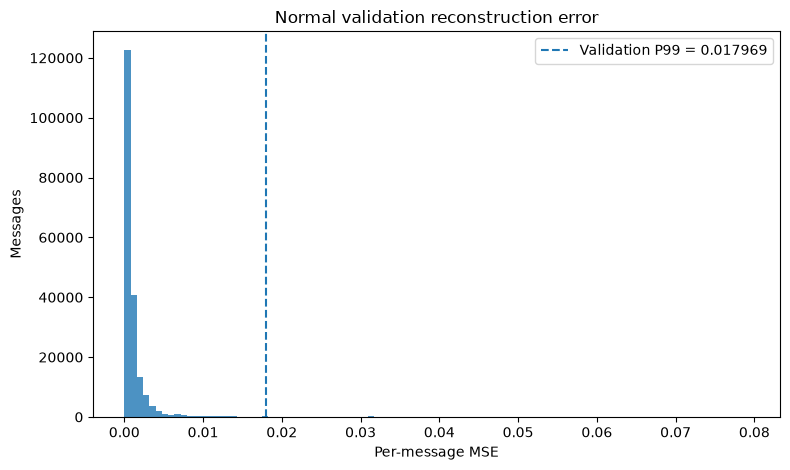

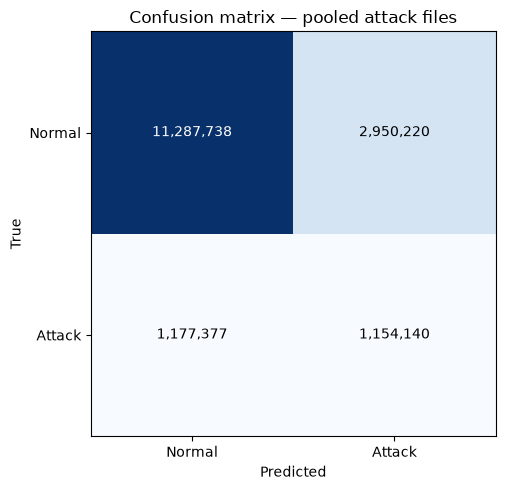

In [178]:
OUT = Path('results_tuned')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(8,4.8))
plt.hist(val_scores, bins=100, alpha=.8)
plt.axvline(threshold, linestyle='--',label=f'Validation P{PERCENTILE:g} = {threshold:.5g}')
plt.title('Normal validation reconstruction error')
plt.xlabel('Per-message MSE')
plt.ylabel('Messages')
plt.legend()
plt.tight_layout()
plt.savefig(FIG/'01_validation_error_threshold.png',dpi=160)
plt.show()

cm = [[pooled['TN'], pooled['FP']], [pooled['FN'], pooled['TP']]]
cm = np.array(cm)
plt.figure(figsize=(5.6,5))
plt.imshow(cm, cmap='Blues')
plt.xticks([0,1],['Normal','Attack'])
plt.yticks([0,1],['Normal','Attack'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix — pooled attack files')
for i in range(2):
    for j in range(2):
        plt.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='white' if cm[i,j] > cm.max()/2 else 'black')
plt.tight_layout()
plt.savefig(FIG/'02_confusion_matrix.png',dpi=160)
plt.show()

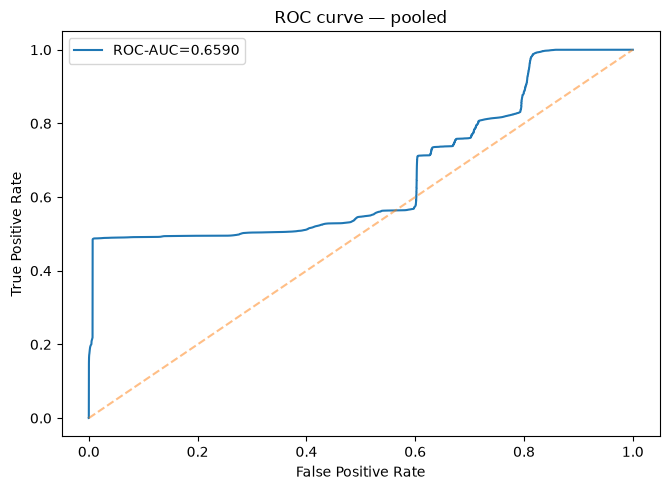

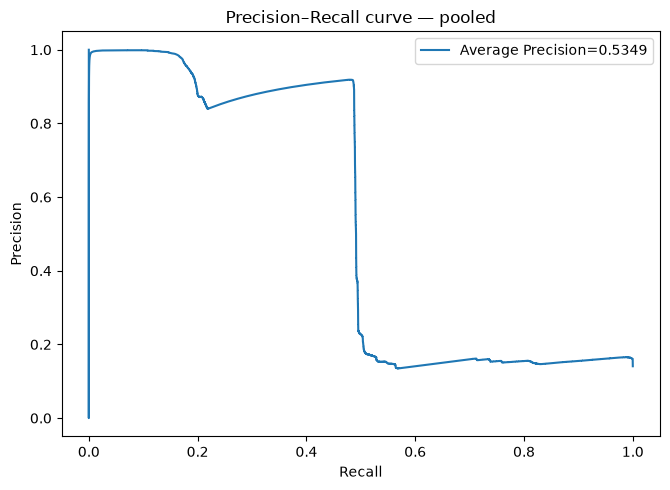

In [179]:
fpr,tpr,_ = roc_curve(all_labels, all_scores)
plt.figure(figsize=(6.8,5))
plt.plot(fpr,tpr,label=f"ROC-AUC={pooled['roc_auc']:.4f}")
plt.plot([0,1],[0,1],'--',alpha=.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve — pooled')
plt.legend()
plt.tight_layout()
plt.savefig(FIG/'03_roc_curve.png',dpi=160)
plt.show()

prec,rec,_ = precision_recall_curve(all_labels, all_scores)
plt.figure(figsize=(6.8,5))
plt.plot(rec,prec,label=f"Average Precision={pooled['average_precision']:.4f}")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall curve — pooled')
plt.legend()
plt.tight_layout()
plt.savefig(FIG/'04_pr_curve.png',dpi=160)
plt.show()

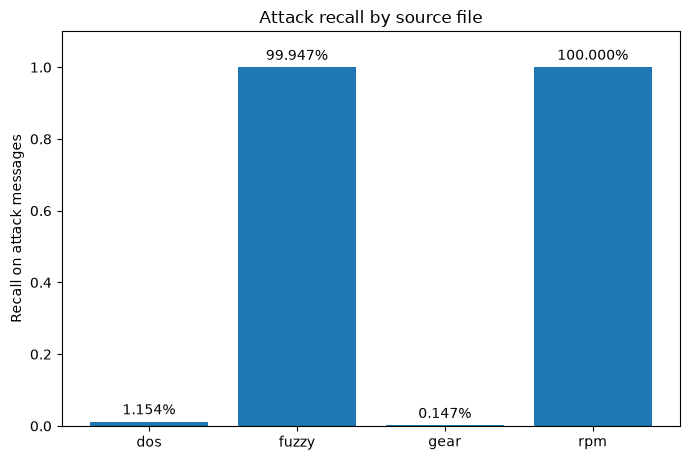

In [180]:
names=list(TESTS)
values=[metrics[n]['recall'] for n in names]
plt.figure(figsize=(7,4.7))
bars = plt.bar(names,values)
plt.bar_label(bars, labels=[f'{v:.3%}' for v in values], padding=3)
plt.ylim(0,1.10)
plt.ylabel('Recall on attack messages')
plt.title('Attack recall by source file')
plt.tight_layout()
plt.savefig(FIG/'05_per_attack_recall.png',dpi=160)
plt.show()

## 8. Save Results
Save computed results separately. The original result files provide a reference for comparison.

In [181]:
threshold_info = {
    'model_filename': MODEL.name,
    'validation_filename': VALIDATION.name,
    'method': 'normal_validation_percentile',
    'percentile': PERCENTILE,
    'threshold': threshold,
    'classification_rule': 'attack if reconstruction_mse > threshold'
}
(OUT / 'frozen_threshold.json').write_text(json.dumps(threshold_info, indent=2))
(OUT / 'evaluation_metrics.json').write_text(
    json.dumps({'threshold': threshold_info, 'metrics': metrics}, indent=2)
)
metrics_table.to_csv(OUT / 'metrics_per_attack.csv', index_label='attack_type')

report = [
    '# CarShield AI — Tuned Temporal Model Evaluation', '',
    f'Validation P99 threshold: {threshold:.12f}', '',
    '## Recall by attack', '',
]
for attack in TESTS:
    row = metrics[attack]
    report.append(f"- {attack}: {row['recall']:.3%} ({row['TP']:,} of {row['attack']:,} attacks)")
report.extend([
    '', f"Pooled recall: {pooled['recall']:.2%}. Pooled F1: {pooled['f1']:.2%}.",
    f"False positive rate among normal test messages: {pooled['fpr']:.2%}.",
    '', 'Pooled results count each message once. The team used the normal validation',
    'recording during model development. Results are reported per message.'
])
(OUT / 'evaluation_report.md').write_text(chr(10).join(report) + chr(10), encoding='utf-8')
print(f'Results saved to {OUT}/')

baseline = json.loads((PROJECT / 'results/baseline/evaluation_metrics.json').read_text())
comparison = []
metric_names = ['accuracy', 'precision', 'recall', 'f1', 'fpr', 'roc_auc', 'average_precision']
for attack, tuned in metrics.items():
    previous = baseline['metrics'][attack]
    if any(tuned[key] != previous[key] for key in ('n', 'normal', 'attack')):
        raise ValueError(f'{attack}: baseline and tuned sample counts differ.')
    for metric in metric_names:
        comparison.append({
            'evaluation': attack,
            'metric': metric,
            'baseline': previous[metric],
            'tuned': tuned[metric],
            'change': tuned[metric] - previous[metric]
        })
comparison = pd.DataFrame(comparison)
comparison.to_csv(OUT / 'baseline_vs_tuned.csv', index=False)
display(comparison[comparison['evaluation'] == 'pooled'].round(6))


Results saved to results_tuned/


,evaluation,metric,baseline,tuned,change
28,pooled,accuracy,0.868122,0.750892,-0.117230
29,pooled,precision,0.534441,0.281199,-0.253242
30,pooled,recall,0.487058,0.495017,0.007958
31,pooled,f1,0.509651,0.358658,-0.150992
32,pooled,fpr,0.069478,0.207208,0.137730
33,pooled,roc_auc,0.773507,0.658993,-0.114513
34,pooled,average_precision,0.597227,0.534862,-0.062365


## Inference example
Use one already scaled validation message in the original feature order.

In [182]:
import sys
sys.path.insert(0, str(PROJECT))
from inference import predict_message

example = pd.read_parquet(VALIDATION, columns=FEATURE_COLUMNS).iloc[0]
print(predict_message(example.to_numpy()))
os.chdir(PROJECT)

{'label': 'Normal', 'reconstruction_error': 0.00017604323059901747, 'threshold': 0.017968580495137495}
